# Severity-Modellierung mit Gamma Regression

Ziel dieses Notebooks ist die Entwicklung und Bewertung eines Gamma-Modells
zur Schätzung der durchschnittlichen Schadenhöhe je Schadenfall.

Die Modellierung verwendet den bereits festgelegten gemeinsamen
Policy-Level-Train/Test-Split. Für die Severity-Analyse werden ausschließlich
fachlich konsistente Schadenpolicen berücksichtigt.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd


PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "policy_curated.pq"
SPLIT_PATH = PROJECT_ROOT / "data" / "processed" / "policy_train_test_split.pq"

print(f"Data exists:  {DATA_PATH.exists()}")
print(f"Split exists: {SPLIT_PATH.exists()}")

Data exists:  True
Split exists: True


## Gemeinsamer Split und Severity-Datengrundlage

Der bereits gespeicherte Policy-Level-Train/Test-Split wird unverändert
übernommen und mit dem Curated-Datensatz verknüpft.

Für die Severity-Modellierung wird anschließend eine fachlich konsistente
Teilmenge der Schadenpolicen gebildet.

In [2]:
df = pd.read_parquet(DATA_PATH)
split_assignment = pd.read_parquet(SPLIT_PATH)

df["IDpol"] = df["IDpol"].astype("int64")
split_assignment["IDpol"] = split_assignment["IDpol"].astype("int64")

df_model = df.merge(
    split_assignment,
    on="IDpol",
    how="left",
    validate="one_to_one",
)

print(f"Curated rows:        {len(df):,}")
print(f"Split rows:          {len(split_assignment):,}")
print(f"Merged rows:         {len(df_model):,}")
print(f"Missing split labels:{df_model['split'].isna().sum():,}")

print("\nSplit counts:")
print(df_model["split"].value_counts())

Curated rows:        678,013
Split rows:          678,013
Merged rows:         678,013
Missing split labels:0

Split counts:
split
train    542410
test     135603
Name: count, dtype: int64


### Auswahl der Severity-geeigneten Policen

Für die Severity-Modellierung werden ausschließlich Policen berücksichtigt,
für die eine positive und fachlich konsistente Schadenhöhe vorliegt.

Policen mit fehlenden Severity-Informationen oder einem Widerspruch zwischen
`ClaimNb` und den vorhandenen Schadenzeilen werden ausgeschlossen.

In [3]:
severity_mask = (
    df_model["ClaimNb"].gt(0)
    & df_model["total_claim_amount"].notna()
    & df_model["total_claim_amount"].gt(0)
    & ~df_model["missing_severity"]
    & ~df_model["claim_count_mismatch"]
)

severity_df = (
    df_model.loc[severity_mask]
    .copy()
)

print("=== Severity Eligibility ===")
print(f"Eligible policies: {len(severity_df):,}")

print("\nSplit counts:")
print(severity_df["split"].value_counts())

print("\n=== Basic Checks ===")
print(f"Missing total_claim_amount: {severity_df['total_claim_amount'].isna().sum():,}")
print(f"Non-positive ClaimNb:       {(severity_df['ClaimNb'] <= 0).sum():,}")
print(f"Non-positive claim amount:  {(severity_df['total_claim_amount'] <= 0).sum():,}")
print(f"Missing severity flag:      {severity_df['missing_severity'].sum():,}")
print(f"Claim-count mismatch:       {severity_df['claim_count_mismatch'].sum():,}")

=== Severity Eligibility ===
Eligible policies: 24,943

Split counts:
split
train    19944
test      4999
Name: count, dtype: int64

=== Basic Checks ===
Missing total_claim_amount: 0
Non-positive ClaimNb:       0
Non-positive claim amount:  0
Missing severity flag:      0
Claim-count mismatch:       0


## Vorbereitung der Severity-Zielvariable

Die durchschnittliche Schadenhöhe je Schadenfall wird als Zielvariable
des Gamma-Modells verwendet.

\[
y = \frac{total\_claim\_amount}{ClaimNb}
\]

Die Anzahl der Schäden (`ClaimNb`) wird dabei als Gewicht verwendet, damit
Policen mit mehreren beobachteten Schäden entsprechend stärker berücksichtigt
werden.

In [4]:
severity_df["observed_severity_target"] = (
    severity_df["total_claim_amount"]
    / severity_df["ClaimNb"]
)

severity_train = (
    severity_df[severity_df["split"] == "train"]
    .copy()
)

severity_test = (
    severity_df[severity_df["split"] == "test"]
    .copy()
)

print("=== Severity Target ===")
print(f"Train policies: {len(severity_train):,}")
print(f"Test policies:  {len(severity_test):,}")

print("\n=== Target Safety Check ===")
print(
    f"Missing target: "
    f"{severity_df['observed_severity_target'].isna().sum():,}"
)
print(
    f"Non-positive target: "
    f"{(severity_df['observed_severity_target'] <= 0).sum():,}"
)

print("\n=== Severity Distribution ===")

severity_stats = severity_df[
    "observed_severity_target"
].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
)

display(severity_stats.to_frame("severity"))

=== Severity Target ===
Train policies: 19,944
Test policies:  4,999

=== Target Safety Check ===
Missing target: 0
Non-positive target: 0

=== Severity Distribution ===


,severity
count,2.494300e+04
mean,2.221446e+03
std,2.899315e+04
min,1.000000e+00
50%,1.172000e+03
75%,1.228080e+03
90%,2.738244e+03
95%,4.651168e+03
99%,1.632717e+04
99.9%,1.333089e+05


### Vergleich der Severity-Verteilung in Train und Test

Vor der Modellierung wird geprüft, ob die Verteilung der durchschnittlichen
Schadenhöhe in Trainings- und Testdaten vergleichbar ist.

Aufgrund der stark rechtsschiefen Verteilung werden neben dem Mittelwert
insbesondere Median und hohe Quantile betrachtet.

In [5]:
severity_distribution_compare = pd.DataFrame({
    "train": severity_train["observed_severity_target"].describe(
        percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
    ),
    "test": severity_test["observed_severity_target"].describe(
        percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
    ),
})

display(severity_distribution_compare)

,train,test
count,1.994400e+04,4999.000000
mean,2.265876e+03,2044.185203
std,3.208204e+04,9378.853835
min,1.000000e+00,1.490000
50%,1.172000e+03,1172.000000
90%,2.724515e+03,2781.898000
95%,4.667355e+03,4621.621500
99%,1.625202e+04,16524.095600
99.9%,1.291397e+05,182885.591940
max,4.075401e+06,301635.490000


**Ergebnis:** Die zentrale Severity-Verteilung ist zwischen Train und Test
weitgehend vergleichbar. Median sowie das 90., 95. und 99. Perzentil liegen
auf einem ähnlichen Niveau.

Unterschiede bei Mittelwert, Standardabweichung und Maximum werden vor allem
durch wenige extreme Großschäden verursacht. Dieser Heavy-Tail-Effekt wird
bei der Modellbewertung ausdrücklich berücksichtigt.

## Feature-Auswahl und Leakage-Prüfung

Vor der Gamma-Modellierung werden die verfügbaren Variablen erneut nach ihrer
fachlichen Rolle geprüft. Es werden ausschließlich Merkmale verwendet, die
unabhängig von der später realisierten Schadenhöhe verfügbar sind.

Schadeninformationen, Data-Quality-Metadaten und technische Variablen werden
nicht als Prädiktoren verwendet.

In [6]:
severity_feature_roles = pd.DataFrame([
    ("IDpol", "Identifier", "Nein"),
    ("ClaimNb", "Weight / Outcome Information", "Nein"),
    ("Exposure", "Exposure", "Nein"),

    ("Area", "Candidate", "Prüfen"),
    ("VehPower", "Candidate", "Prüfen"),
    ("VehAge", "Candidate", "Prüfen"),
    ("DrivAge", "Candidate", "Prüfen"),
    ("BonusMalus", "Candidate", "Prüfen"),
    ("VehBrand", "Candidate", "Prüfen"),
    ("VehGas", "Candidate", "Prüfen"),
    ("Density", "Candidate", "Prüfen"),
    ("Region", "Candidate", "Prüfen"),

    ("exposure_capped", "DQ / Processing Flag", "Nein"),
    ("high_claim_count", "Outcome-derived Flag", "Nein"),
    ("total_claim_amount", "Target Leakage", "Nein"),
    ("claim_record_count", "Outcome Information", "Nein"),
    ("claim_count_mismatch", "DQ / Post-Outcome", "Nein"),
    ("missing_severity", "DQ / Post-Outcome", "Nein"),

    ("observed_claim_frequency", "Outcome / Leakage", "Nein"),
    ("observed_severity", "Target Leakage", "Nein"),
    ("observed_pure_premium", "Target Leakage", "Nein"),

    ("driver_age_group", "Engineered Candidate", "Prüfen"),
    ("vehicle_age_group", "Engineered Candidate", "Prüfen"),
    ("bonus_malus_segment", "Engineered Candidate", "Prüfen"),
    ("log_density", "Engineered Candidate", "Prüfen"),

    ("split", "Split Metadata", "Nein"),
    ("observed_severity_target", "Target", "Nein"),
], columns=["column", "role", "severity_predictor"])

display(severity_feature_roles)

,column,role,severity_predictor
0,IDpol,Identifier,Nein
1,ClaimNb,Weight / Outcome Information,Nein
2,Exposure,Exposure,Nein
3,Area,Candidate,Prüfen
4,VehPower,Candidate,Prüfen
5,VehAge,Candidate,Prüfen
6,DrivAge,Candidate,Prüfen
7,BonusMalus,Candidate,Prüfen
8,VehBrand,Candidate,Prüfen
9,VehGas,Candidate,Prüfen


### Prüfung der potenziellen Modellmerkmale

Vor der Modellspezifikation werden die potenziellen Severity-Merkmale auf
fehlende Werte und unbekannte Kategorien im Testdatensatz geprüft.

Die endgültige Darstellung von Alter, Bonus-Malus und Density wird erst
anschließend innerhalb der Trainingsdaten verglichen.

In [7]:
severity_candidate_features = [
    "Area",
    "VehPower",
    "VehAge",
    "DrivAge",
    "BonusMalus",
    "VehBrand",
    "VehGas",
    "Density",
    "Region",
    "driver_age_group",
    "vehicle_age_group",
    "bonus_malus_segment",
    "log_density",
]

severity_categorical_candidates = [
    "Area",
    "VehPower",
    "VehBrand",
    "VehGas",
    "Region",
    "driver_age_group",
    "vehicle_age_group",
    "bonus_malus_segment",
]

print("=== Missing Values ===")

severity_missing = (
    severity_df[severity_candidate_features]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print(severity_missing)


print("\n=== Unseen Categories in Test ===")

for col in severity_categorical_candidates:
    train_categories = set(
        severity_train[col].dropna().astype(str).unique()
    )

    test_categories = set(
        severity_test[col].dropna().astype(str).unique()
    )

    unseen = test_categories - train_categories

    print(f"{col}: {len(unseen)} unseen categories")

    if unseen:
        print(f"  {sorted(unseen)}")

=== Missing Values ===
Area                   0
VehPower               0
VehAge                 0
DrivAge                0
BonusMalus             0
VehBrand               0
VehGas                 0
Density                0
Region                 0
driver_age_group       0
vehicle_age_group      0
bonus_malus_segment    0
log_density            0
dtype: int64

=== Unseen Categories in Test ===
Area: 0 unseen categories
VehPower: 0 unseen categories
VehBrand: 0 unseen categories


VehGas: 0 unseen categories
Region: 0 unseen categories
driver_age_group: 0 unseen categories
vehicle_age_group: 0 unseen categories
bonus_malus_segment: 0 unseen categories


## Baseline-Modell für die Schadenhöhe

Als Referenz wird zunächst eine konstante durchschnittliche Schadenhöhe
aus dem Trainingsportfolio verwendet.

Die durchschnittliche Schadenhöhe wird mit der Anzahl der beobachteten
Schäden gewichtet. Dadurch entspricht die Baseline der durchschnittlichen
Schadenhöhe je Schadenfall im Trainingsdatensatz.

In [8]:
from sklearn.metrics import mean_gamma_deviance


y_severity_train = severity_train["observed_severity_target"].copy()
y_severity_test = severity_test["observed_severity_target"].copy()

w_severity_train = severity_train["ClaimNb"].copy()
w_severity_test = severity_test["ClaimNb"].copy()


baseline_severity = np.average(
    y_severity_train,
    weights=w_severity_train,
)

baseline_severity_pred = np.full(
    len(severity_test),
    baseline_severity,
    dtype=float,
)

baseline_gamma_deviance = mean_gamma_deviance(
    y_severity_test,
    baseline_severity_pred,
    sample_weight=w_severity_test,
)


actual_test_claim_amount = (
    severity_test["total_claim_amount"].sum()
)

baseline_expected_claim_amount = (
    baseline_severity_pred
    * w_severity_test.to_numpy()
).sum()


print("=== Severity Baseline ===")
print(f"Train weighted mean severity: {baseline_severity:,.2f}")
print(f"Mean Gamma Deviance:          {baseline_gamma_deviance:.6f}")

print("\n=== Test Portfolio Check ===")
print(f"Actual claim amount:          {actual_test_claim_amount:,.2f}")
print(f"Baseline expected amount:     {baseline_expected_claim_amount:,.2f}")
print(
    f"Difference:                   "
    f"{baseline_expected_claim_amount - actual_test_claim_amount:,.2f}"
)

=== Severity Baseline ===
Train weighted mean severity: 2,311.91
Mean Gamma Deviance:          1.543630

=== Test Portfolio Check ===
Actual claim amount:          11,055,690.67
Baseline expected amount:     12,280,869.01
Difference:                   1,225,178.34


## Cross-Validation für das Severity-Modell

Die Modellauswahl erfolgt ausschließlich innerhalb des Trainingsdatensatzes.
Dazu wird eine reproduzierbare 5-Fold-Cross-Validation verwendet.

Aufgrund der stark rechtsschiefen Schadenhöhenverteilung werden die
Verteilungen der Validierungsfolds vor der Modelloptimierung kontrolliert.
Der Holdout-Testdatensatz bleibt von der Modellauswahl ausgeschlossen.

In [9]:
from sklearn.model_selection import KFold


severity_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

print("=== 5-Fold Severity Cross-Validation Check ===")

for fold, (fit_idx, val_idx) in enumerate(
    severity_cv.split(severity_train),
    start=1,
):
    fold_fit = severity_train.iloc[fit_idx]
    fold_val = severity_train.iloc[val_idx]

    fit_weighted_severity = np.average(
        fold_fit["observed_severity_target"],
        weights=fold_fit["ClaimNb"],
    )

    val_weighted_severity = np.average(
        fold_val["observed_severity_target"],
        weights=fold_val["ClaimNb"],
    )

    print(f"\nFold {fold}")
    print(f"  Fit policies:          {len(fold_fit):,}")
    print(f"  Validation policies:   {len(fold_val):,}")
    print(f"  Validation claims:     {fold_val['ClaimNb'].sum():,.0f}")
    print(f"  Fit weighted severity: {fit_weighted_severity:,.2f}")
    print(f"  Val weighted severity: {val_weighted_severity:,.2f}")
    print(
        f"  Val 99% severity:      "
        f"{fold_val['observed_severity_target'].quantile(0.99):,.2f}"
    )

=== 5-Fold Severity Cross-Validation Check ===

Fold 1
  Fit policies:          15,955
  Validation policies:   3,989
  Validation claims:     4,205
  Fit weighted severity: 2,348.57
  Val weighted severity: 2,164.34
  Val 99% severity:      12,447.85

Fold 2
  Fit policies:          15,955
  Validation policies:   3,989
  Validation claims:     4,241
  Fit weighted severity: 2,070.47
  Val weighted severity: 3,273.46
  Val 99% severity:      15,000.00

Fold 3
  Fit policies:          15,955
  Validation policies:   3,989
  Validation claims:     4,221
  Fit weighted severity: 2,423.31
  Val weighted severity: 1,865.62
  Val 99% severity:      15,007.13

Fold 4
  Fit policies:          15,955
  Validation policies:   3,989
  Validation claims:     4,245
  Fit weighted severity: 2,380.15
  Val weighted severity: 2,040.47
  Val 99% severity:      20,220.11

Fold 5
  Fit policies:          15,956
  Validation policies:   3,988
  Validation claims:     4,219
  Fit weighted severity: 2,336.

**Ergebnis:** Die Anzahl der Policen und Schadenfälle ist über die fünf
Validierungsfolds vergleichbar. Die mittlere Schadenhöhe schwankt dagegen
deutlich stärker.

Diese Unterschiede werden durch die ausgeprägte Heavy-Tail-Struktur der
Schadenhöhen verursacht und müssen bei der Cross-Validation berücksichtigt
werden.

### Vergleich alternativer Feature-Spezifikationen

Für das Severity-Modell werden drei unterschiedliche Darstellungen von
Fahrer-Alter, Fahrzeugalter und Bonus-Malus verglichen:

- **Grouped:** Verwendung der abgeleiteten Kategorien.
- **Raw Linear:** Verwendung der ursprünglichen numerischen Variablen.
- **Spline:** Flexible nichtlineare Modellierung der Rohvariablen.

Alle übrigen Modellmerkmale bleiben unverändert. Die Modellauswahl erfolgt
ausschließlich innerhalb der Trainingsdaten.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, SplineTransformer
from sklearn.linear_model import GammaRegressor
from sklearn.pipeline import Pipeline


severity_fixed_categorical = [
    "VehPower",
    "VehBrand",
    "VehGas",
    "Region",
]

severity_grouped_features = [
    "driver_age_group",
    "vehicle_age_group",
    "bonus_malus_segment",
]

severity_raw_numeric = [
    "DrivAge",
    "VehAge",
    "BonusMalus",
]

severity_density_feature = [
    "log_density",
]

severity_comparison_features = (
    severity_fixed_categorical
    + severity_grouped_features
    + severity_raw_numeric
    + severity_density_feature
)

X_severity_train = severity_train[
    severity_comparison_features
].copy()

X_severity_test = severity_test[
    severity_comparison_features
].copy()

print(f"X severity train: {X_severity_train.shape}")
print(f"X severity test:  {X_severity_test.shape}")

X severity train: (19944, 11)
X severity test:  (4999, 11)


### Cross-Validation der Severity-Spezifikationen

Die drei Feature-Spezifikationen werden auf identischen Cross-Validation-Folds
verglichen.

Als Auswahlkriterium dient die mit `ClaimNb` gewichtete Mean Gamma Deviance.
Ein niedrigerer Wert bedeutet eine bessere Validierungsleistung.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, SplineTransformer
from sklearn.linear_model import GammaRegressor
from sklearn.pipeline import Pipeline


# Gemeinsame Feature-Gruppen
severity_fixed_categorical = [
    "VehPower",
    "VehBrand",
    "VehGas",
    "Region",
]

severity_grouped_features = [
    "driver_age_group",
    "vehicle_age_group",
    "bonus_malus_segment",
]

severity_raw_numeric = [
    "DrivAge",
    "VehAge",
    "BonusMalus",
]

severity_density_feature = [
    "log_density",
]


# A — Grouped
severity_preprocessor_grouped = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first",
            ),
            severity_fixed_categorical + severity_grouped_features,
        ),
        (
            "numeric",
            "passthrough",
            severity_density_feature,
        ),
    ],
    remainder="drop",
)


# B — Raw Linear
severity_preprocessor_raw = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first",
            ),
            severity_fixed_categorical,
        ),
        (
            "numeric",
            "passthrough",
            severity_raw_numeric + severity_density_feature,
        ),
    ],
    remainder="drop",
)


# C — Spline
severity_preprocessor_spline = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first",
            ),
            severity_fixed_categorical,
        ),
        (
            "spline",
            SplineTransformer(
                n_knots=5,
                degree=3,
                include_bias=False,
            ),
            severity_raw_numeric,
        ),
        (
            "numeric",
            "passthrough",
            severity_density_feature,
        ),
    ],
    remainder="drop",
)


severity_model_specifications = {
    "Grouped": Pipeline(
        steps=[
            ("preprocessor", severity_preprocessor_grouped),
            (
                "model",
                GammaRegressor(
                    alpha=0.0,
                    max_iter=1000,
                ),
            ),
        ]
    ),

    "Raw Linear": Pipeline(
        steps=[
            ("preprocessor", severity_preprocessor_raw),
            (
                "model",
                GammaRegressor(
                    alpha=0.0,
                    max_iter=1000,
                ),
            ),
        ]
    ),

    "Spline": Pipeline(
        steps=[
            ("preprocessor", severity_preprocessor_spline),
            (
                "model",
                GammaRegressor(
                    alpha=0.0,
                    max_iter=1000,
                ),
            ),
        ]
    ),
}

print("Severity model specifications:")
for name in severity_model_specifications:
    print(f"- {name}")

Severity model specifications:
- Grouped
- Raw Linear
- Spline


In [12]:
from sklearn.base import clone


severity_specification_results = []

for model_name, pipeline in severity_model_specifications.items():

    fold_deviances = []

    for fold, (fit_idx, val_idx) in enumerate(
        severity_cv.split(X_severity_train),
        start=1,
    ):
        X_fit = X_severity_train.iloc[fit_idx]
        X_val = X_severity_train.iloc[val_idx]

        y_fit = y_severity_train.iloc[fit_idx]
        y_val = y_severity_train.iloc[val_idx]

        w_fit = w_severity_train.iloc[fit_idx]
        w_val = w_severity_train.iloc[val_idx]

        fold_pipeline = clone(pipeline)

        fold_pipeline.fit(
            X_fit,
            y_fit,
            model__sample_weight=w_fit,
        )

        val_pred = fold_pipeline.predict(X_val)

        fold_deviance = mean_gamma_deviance(
            y_val,
            val_pred,
            sample_weight=w_val,
        )

        fold_deviances.append(fold_deviance)

    severity_specification_results.append({
        "model": model_name,
        "mean_gamma_deviance": np.mean(fold_deviances),
        "std_gamma_deviance": np.std(fold_deviances),
        "fold_1": fold_deviances[0],
        "fold_2": fold_deviances[1],
        "fold_3": fold_deviances[2],
        "fold_4": fold_deviances[3],
        "fold_5": fold_deviances[4],
    })


severity_specification_results_df = (
    pd.DataFrame(severity_specification_results)
    .sort_values("mean_gamma_deviance")
    .reset_index(drop=True)
)

display(severity_specification_results_df)

c:\Users\Mesut\Desktop\kfz-insurance-risk-platform\.venv\Lib\site-packages\sklearn\linear_model\_glm\glm.py:296: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result(
c:\Users\Mesut\Desktop\kfz-insurance-risk-platform\.venv\Lib\site-packages\sklearn\linear_model\_glm\glm.py:296: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result(
c:\Users\Mesut\Desktop\kfz-insurance-risk-platform\.venv

,model,mean_gamma_deviance,std_gamma_deviance,fold_1,fold_2,fold_3,fold_4,fold_5
0,Spline,1.644566,0.231554,1.461838,2.069027,1.424520,1.579526,1.687921
1,Grouped,1.721513,0.300633,1.513569,2.282537,1.449477,1.589823,1.772159
2,Raw Linear,1.795845,0.416275,1.623749,2.619639,1.484536,1.584871,1.666429


In [13]:
import warnings

from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning


print("=== Convergence Diagnostic ===")

for model_name, pipeline in severity_model_specifications.items():

    print(f"\n{model_name}")

    for fold, (fit_idx, val_idx) in enumerate(
        severity_cv.split(X_severity_train),
        start=1,
    ):
        X_fit = X_severity_train.iloc[fit_idx]
        y_fit = y_severity_train.iloc[fit_idx]
        w_fit = w_severity_train.iloc[fit_idx]

        fold_pipeline = clone(pipeline)

        with warnings.catch_warnings(record=True) as caught_warnings:
            warnings.simplefilter("always", ConvergenceWarning)

            fold_pipeline.fit(
                X_fit,
                y_fit,
                model__sample_weight=w_fit,
            )

        convergence_warnings = [
            warning
            for warning in caught_warnings
            if issubclass(warning.category, ConvergenceWarning)
        ]

        n_iter = (
            fold_pipeline
            .named_steps["model"]
            .n_iter_
        )

        print(
            f"  Fold {fold}: "
            f"iterations={n_iter}, "
            f"converged={len(convergence_warnings) == 0}"
        )

=== Convergence Diagnostic ===

Grouped
  Fold 1: iterations=152, converged=True
  Fold 2: iterations=150, converged=True
  Fold 3: iterations=138, converged=True
  Fold 4: iterations=102, converged=True
  Fold 5: iterations=131, converged=True

Raw Linear
  Fold 1: iterations=1000, converged=False
  Fold 2: iterations=1000, converged=False
  Fold 3: iterations=1000, converged=False
  Fold 4: iterations=1000, converged=False
  Fold 5: iterations=1000, converged=False

Spline
  Fold 1: iterations=504, converged=True
  Fold 2: iterations=362, converged=True
  Fold 3: iterations=435, converged=True
  Fold 4: iterations=385, converged=True
  Fold 5: iterations=420, converged=True


In [14]:
from sklearn.preprocessing import StandardScaler


severity_preprocessor_raw_scaled = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first",
            ),
            severity_fixed_categorical,
        ),
        (
            "numeric",
            StandardScaler(),
            severity_raw_numeric + severity_density_feature,
        ),
    ],
    remainder="drop",
)


severity_model_specifications["Raw Linear"] = Pipeline(
    steps=[
        (
            "preprocessor",
            severity_preprocessor_raw_scaled,
        ),
        (
            "model",
            GammaRegressor(
                alpha=0.0,
                max_iter=1000,
            ),
        ),
    ]
)

print("Raw Linear specification updated with StandardScaler.")

Raw Linear specification updated with StandardScaler.


In [15]:
print("=== Raw Linear Convergence Re-Check ===")

raw_pipeline = severity_model_specifications["Raw Linear"]

for fold, (fit_idx, val_idx) in enumerate(
    severity_cv.split(X_severity_train),
    start=1,
):
    X_fit = X_severity_train.iloc[fit_idx]
    y_fit = y_severity_train.iloc[fit_idx]
    w_fit = w_severity_train.iloc[fit_idx]

    fold_pipeline = clone(raw_pipeline)

    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always", ConvergenceWarning)

        fold_pipeline.fit(
            X_fit,
            y_fit,
            model__sample_weight=w_fit,
        )

    convergence_warnings = [
        warning
        for warning in caught_warnings
        if issubclass(warning.category, ConvergenceWarning)
    ]

    n_iter = fold_pipeline.named_steps["model"].n_iter_

    print(
        f"Fold {fold}: "
        f"iterations={n_iter}, "
        f"converged={len(convergence_warnings) == 0}"
    )

=== Raw Linear Convergence Re-Check ===
Fold 1: iterations=64, converged=True
Fold 2: iterations=76, converged=True
Fold 3: iterations=71, converged=True
Fold 4: iterations=68, converged=True
Fold 5: iterations=71, converged=True


In [16]:
severity_specification_results = []

for model_name, pipeline in severity_model_specifications.items():

    fold_deviances = []

    for fold, (fit_idx, val_idx) in enumerate(
        severity_cv.split(X_severity_train),
        start=1,
    ):
        X_fit = X_severity_train.iloc[fit_idx]
        X_val = X_severity_train.iloc[val_idx]

        y_fit = y_severity_train.iloc[fit_idx]
        y_val = y_severity_train.iloc[val_idx]

        w_fit = w_severity_train.iloc[fit_idx]
        w_val = w_severity_train.iloc[val_idx]

        fold_pipeline = clone(pipeline)

        fold_pipeline.fit(
            X_fit,
            y_fit,
            model__sample_weight=w_fit,
        )

        val_pred = fold_pipeline.predict(X_val)

        fold_deviance = mean_gamma_deviance(
            y_val,
            val_pred,
            sample_weight=w_val,
        )

        fold_deviances.append(fold_deviance)

    severity_specification_results.append({
        "model": model_name,
        "mean_gamma_deviance": np.mean(fold_deviances),
        "std_gamma_deviance": np.std(fold_deviances),
        "fold_1": fold_deviances[0],
        "fold_2": fold_deviances[1],
        "fold_3": fold_deviances[2],
        "fold_4": fold_deviances[3],
        "fold_5": fold_deviances[4],
    })


severity_specification_results_df = (
    pd.DataFrame(severity_specification_results)
    .sort_values("mean_gamma_deviance")
    .reset_index(drop=True)
)

display(severity_specification_results_df)

,model,mean_gamma_deviance,std_gamma_deviance,fold_1,fold_2,fold_3,fold_4,fold_5
0,Spline,1.644566,0.231554,1.461838,2.069027,1.424520,1.579526,1.687921
1,Grouped,1.721513,0.300633,1.513569,2.282537,1.449477,1.589823,1.772159
2,Raw Linear,1.796157,0.417212,1.623772,2.621878,1.484436,1.584867,1.665833


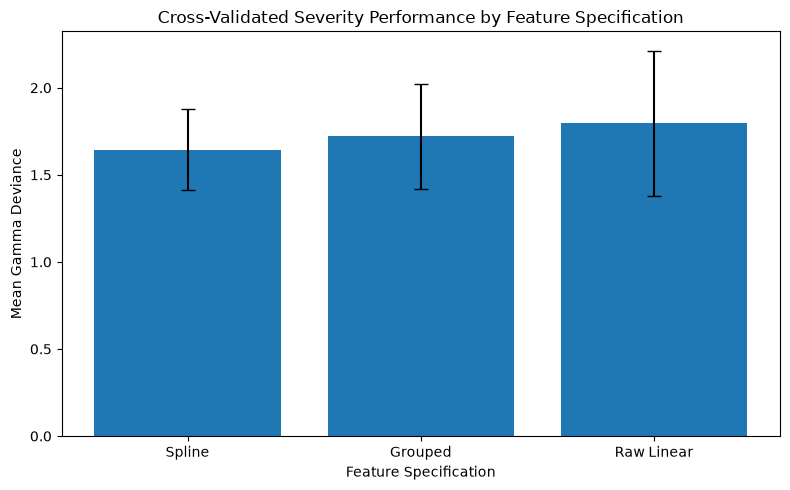

In [17]:
import matplotlib.pyplot as plt

severity_spec_plot = (
    severity_specification_results_df
    .sort_values("mean_gamma_deviance")
    .copy()
)

plt.figure(figsize=(8, 5))

plt.bar(
    severity_spec_plot["model"],
    severity_spec_plot["mean_gamma_deviance"],
    yerr=severity_spec_plot["std_gamma_deviance"],
    capsize=5,
)

plt.ylabel("Mean Gamma Deviance")
plt.xlabel("Feature Specification")
plt.title("Cross-Validated Severity Performance by Feature Specification")

plt.tight_layout()
plt.show()

**Ergebnis:** Die Spline-Spezifikation erzielt die niedrigste mittlere
Gamma Deviance und zeigt zugleich die geringste Streuung zwischen den
Validierungsfolds.

Aufgrund der ausgeprägten Heavy-Tail-Struktur bleiben die Unterschiede
zwischen den Folds jedoch deutlich. Für die weitere Optimierung wird daher
die Spline-Spezifikation verwendet.

### Optimierung der Spline-Spezifikation

Für das Severity-Modell werden die Anzahl der Spline-Knoten, der Grad der
Spline-Funktionen und die Regularisierungsstärke innerhalb der Trainingsdaten
gemeinsam optimiert.

Die Auswahl erfolgt anhand der mit `ClaimNb` gewichteten Mean Gamma Deviance
in der 5-Fold-Cross-Validation. Zusätzlich wird die Streuung zwischen den
Folds berücksichtigt.

In [18]:
from itertools import product


severity_n_knots_values = [4, 5, 6]
severity_degree_values = [2, 3]
severity_alpha_values = [0.0, 0.0001, 0.001, 0.01, 0.1]

severity_tuning_results = []

for n_knots, degree, alpha in product(
    severity_n_knots_values,
    severity_degree_values,
    severity_alpha_values,
):

    fold_deviances = []

    for fit_idx, val_idx in severity_cv.split(X_severity_train):

        X_fit = X_severity_train.iloc[fit_idx]
        X_val = X_severity_train.iloc[val_idx]

        y_fit = y_severity_train.iloc[fit_idx]
        y_val = y_severity_train.iloc[val_idx]

        w_fit = w_severity_train.iloc[fit_idx]
        w_val = w_severity_train.iloc[val_idx]

        tuning_preprocessor = ColumnTransformer(
            transformers=[
                (
                    "categorical",
                    OneHotEncoder(
                        handle_unknown="ignore",
                        drop="first",
                    ),
                    severity_fixed_categorical,
                ),
                (
                    "spline",
                    SplineTransformer(
                        n_knots=n_knots,
                        degree=degree,
                        include_bias=False,
                    ),
                    severity_raw_numeric,
                ),
                (
                    "numeric",
                    "passthrough",
                    severity_density_feature,
                ),
            ],
            remainder="drop",
        )

        tuning_pipeline = Pipeline(
            steps=[
                ("preprocessor", tuning_preprocessor),
                (
                    "model",
                    GammaRegressor(
                        alpha=alpha,
                        max_iter=1000,
                    ),
                ),
            ]
        )

        tuning_pipeline.fit(
            X_fit,
            y_fit,
            model__sample_weight=w_fit,
        )

        val_pred = tuning_pipeline.predict(X_val)

        fold_deviance = mean_gamma_deviance(
            y_val,
            val_pred,
            sample_weight=w_val,
        )

        fold_deviances.append(fold_deviance)

    severity_tuning_results.append({
        "n_knots": n_knots,
        "degree": degree,
        "alpha": alpha,
        "mean_gamma_deviance": np.mean(fold_deviances),
        "std_gamma_deviance": np.std(fold_deviances),
    })


severity_tuning_df = (
    pd.DataFrame(severity_tuning_results)
    .sort_values(
        ["mean_gamma_deviance", "std_gamma_deviance"]
    )
    .reset_index(drop=True)
)

display(severity_tuning_df)

,n_knots,degree,alpha,mean_gamma_deviance,std_gamma_deviance
0,6,3,0.0000,1.637578,0.218410
1,5,3,0.0000,1.644566,0.231554
2,6,3,0.0001,1.658606,0.266019
3,6,2,0.0001,1.663331,0.258654
4,6,2,0.0000,1.663486,0.255352
5,5,3,0.0001,1.665910,0.275842
6,6,2,0.0010,1.668927,0.280118
7,5,2,0.0000,1.689058,0.283505
8,4,3,0.0000,1.689218,0.279338
9,5,2,0.0010,1.691069,0.301450


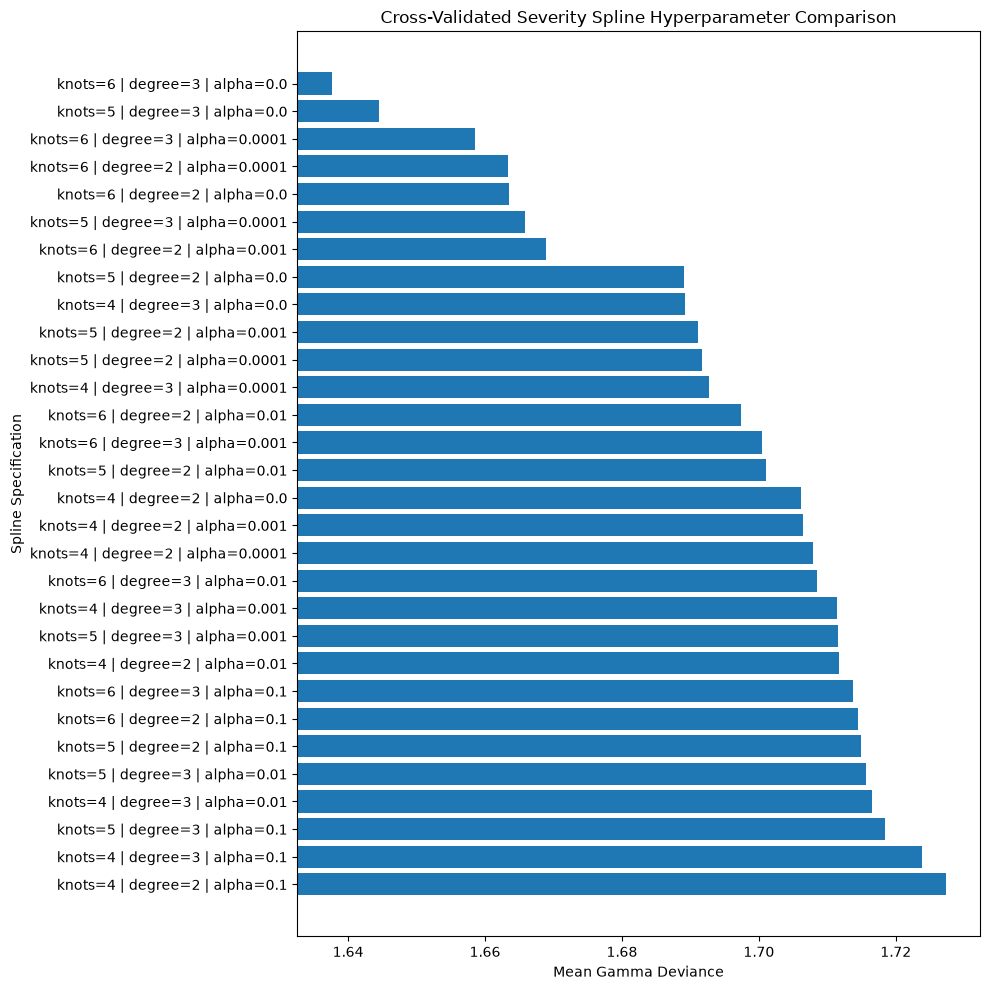

In [19]:
severity_tuning_plot = severity_tuning_df.copy()

severity_tuning_plot["specification"] = (
    "knots=" + severity_tuning_plot["n_knots"].astype(str)
    + " | degree=" + severity_tuning_plot["degree"].astype(str)
    + " | alpha=" + severity_tuning_plot["alpha"].astype(str)
)

severity_tuning_plot = severity_tuning_plot.sort_values(
    "mean_gamma_deviance",
    ascending=False,
)

plt.figure(figsize=(10, 10))

plt.barh(
    severity_tuning_plot["specification"],
    severity_tuning_plot["mean_gamma_deviance"],
)

plt.xlabel("Mean Gamma Deviance")
plt.ylabel("Spline Specification")
plt.title("Cross-Validated Severity Spline Hyperparameter Comparison")

plt.xlim(
    severity_tuning_plot["mean_gamma_deviance"].min() - 0.005,
    severity_tuning_plot["mean_gamma_deviance"].max() + 0.005,
)

plt.tight_layout()
plt.show()

**Ergebnis:** Die beste Cross-Validation-Leistung erzielt die Spline-
Spezifikation mit sechs Knoten, Grad 3 und ohne zusätzliche Regularisierung
(`alpha=0`).

Die gewählte Konfiguration erreicht sowohl die niedrigste mittlere Gamma
Deviance als auch eine vergleichsweise geringe Streuung zwischen den
Validierungsfolds.

## Finales Severity-Modell

Auf Basis der Cross-Validation wird die finale Gamma-Spezifikation mit
sechs Spline-Knoten, Grad 3 und ohne zusätzliche Regularisierung festgelegt.

Das Modell wird auf dem vollständigen Severity-Trainingsdatensatz geschätzt
und anschließend auf dem gemeinsamen Holdout-Testdatensatz bewertet.

In [20]:
final_severity_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first",
            ),
            severity_fixed_categorical,
        ),
        (
            "spline",
            SplineTransformer(
                n_knots=6,
                degree=3,
                include_bias=False,
            ),
            severity_raw_numeric,
        ),
        (
            "numeric",
            "passthrough",
            severity_density_feature,
        ),
    ],
    remainder="drop",
)

final_severity_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            final_severity_preprocessor,
        ),
        (
            "model",
            GammaRegressor(
                alpha=0.0,
                max_iter=1000,
            ),
        ),
    ]
)

final_severity_pipeline.fit(
    X_severity_train,
    y_severity_train,
    model__sample_weight=w_severity_train,
)

print("Final Gamma severity model fitted successfully.")

Final Gamma severity model fitted successfully.


### Prüfung der finalen Severity-Prognosen

Die Prognosen des finalen Gamma-Modells werden auf dem Holdout-Testdatensatz
zunächst technisch validiert.

Dabei werden insbesondere fehlende, unendliche oder nicht-positive
Vorhersagen ausgeschlossen.

In [21]:
final_severity_pred_test = final_severity_pipeline.predict(
    X_severity_test
)

final_gamma_model = (
    final_severity_pipeline
    .named_steps["model"]
)

print("=== Final Severity Prediction Sanity Check ===")
print(f"Predictions:          {len(final_severity_pred_test):,}")
print(f"NaN predictions:      {np.isnan(final_severity_pred_test).sum():,}")
print(f"Infinite predictions: {np.isinf(final_severity_pred_test).sum():,}")
print(f"Non-positive preds:   {(final_severity_pred_test <= 0).sum():,}")

print("\n=== Prediction Range ===")
print(f"Minimum: {final_severity_pred_test.min():,.2f}")
print(f"Mean:    {final_severity_pred_test.mean():,.2f}")
print(f"Median:  {np.median(final_severity_pred_test):,.2f}")
print(f"Maximum: {final_severity_pred_test.max():,.2f}")

print("\n=== Optimizer ===")
print(f"Iterations used: {final_gamma_model.n_iter_}")

=== Final Severity Prediction Sanity Check ===
Predictions:          4,999
NaN predictions:      0
Infinite predictions: 0
Non-positive preds:   0

=== Prediction Range ===
Minimum: 598.21
Mean:    2,230.08
Median:  1,920.62
Maximum: 39,935.89

=== Optimizer ===
Iterations used: 294


### Finale Bewertung des Severity-Modells

Die finale Modellleistung wird auf dem Holdout-Testdatensatz bewertet.
Als zentrale Kennzahl wird die mit `ClaimNb` gewichtete Mean Gamma Deviance
verwendet.

Zusätzlich werden der Gamma-D²-Score, die durchschnittliche Schadenhöhe je
Schadenfall sowie die gesamte prognostizierte Schadenhöhe verglichen.

In [22]:
from sklearn.metrics import d2_tweedie_score


final_gamma_deviance = mean_gamma_deviance(
    y_severity_test,
    final_severity_pred_test,
    sample_weight=w_severity_test,
)

final_gamma_d2 = d2_tweedie_score(
    y_severity_test,
    final_severity_pred_test,
    sample_weight=w_severity_test,
    power=2,
)

improvement_vs_gamma_baseline = (
    (baseline_gamma_deviance - final_gamma_deviance)
    / baseline_gamma_deviance
)

actual_weighted_severity = np.average(
    y_severity_test,
    weights=w_severity_test,
)

predicted_weighted_severity = np.average(
    final_severity_pred_test,
    weights=w_severity_test,
)

actual_claim_amount = severity_test[
    "total_claim_amount"
].sum()

predicted_claim_amount = (
    final_severity_pred_test
    * w_severity_test.to_numpy()
).sum()

claim_amount_difference = (
    predicted_claim_amount - actual_claim_amount
)

claim_amount_difference_pct = (
    claim_amount_difference / actual_claim_amount
)


print("=== Final Severity Holdout Evaluation ===")
print(f"Baseline Mean Gamma Deviance: {baseline_gamma_deviance:.6f}")
print(f"Final Mean Gamma Deviance:    {final_gamma_deviance:.6f}")
print(f"Improvement vs baseline:      {improvement_vs_gamma_baseline:.2%}")
print(f"Gamma D²:                     {final_gamma_d2:.4f}")

print("\n=== Claim-Weighted Severity Comparison ===")
print(f"Actual severity:              {actual_weighted_severity:,.2f}")
print(f"Predicted severity:           {predicted_weighted_severity:,.2f}")

print("\n=== Claim Amount Validation ===")
print(f"Actual claim amount:          {actual_claim_amount:,.2f}")
print(f"Predicted claim amount:       {predicted_claim_amount:,.2f}")
print(f"Difference:                   {claim_amount_difference:,.2f}")
print(f"Difference %:                 {claim_amount_difference_pct:.2%}")

=== Final Severity Holdout Evaluation ===
Baseline Mean Gamma Deviance: 1.543630
Final Mean Gamma Deviance:    1.615760
Improvement vs baseline:      -4.67%
Gamma D²:                     -0.0540

=== Claim-Weighted Severity Comparison ===
Actual severity:              2,081.27
Predicted severity:           2,231.01

=== Claim Amount Validation ===
Actual claim amount:          11,055,690.67
Predicted claim amount:       11,851,115.36
Difference:                   795,424.69
Difference %:                 7.19%


### Vergleich mit der Cross-Validation-Baseline

Die beste Severity-Spezifikation wird zusätzlich gegen eine fold-spezifische
Baseline verglichen.

Die Baseline verwendet in jedem Fold ausschließlich die mit `ClaimNb`
gewichtete mittlere Schadenhöhe des jeweiligen Fit-Datensatzes. Dadurch wird
geprüft, ob die Modellmerkmale tatsächlich zusätzliche Prognoseinformation
für die Schadenhöhe liefern.

In [23]:
cv_baseline_deviances = []
cv_spline_deviances = []

best_severity_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            ColumnTransformer(
                transformers=[
                    (
                        "categorical",
                        OneHotEncoder(
                            handle_unknown="ignore",
                            drop="first",
                        ),
                        severity_fixed_categorical,
                    ),
                    (
                        "spline",
                        SplineTransformer(
                            n_knots=6,
                            degree=3,
                            include_bias=False,
                        ),
                        severity_raw_numeric,
                    ),
                    (
                        "numeric",
                        "passthrough",
                        severity_density_feature,
                    ),
                ],
                remainder="drop",
            ),
        ),
        (
            "model",
            GammaRegressor(
                alpha=0.0,
                max_iter=1000,
            ),
        ),
    ]
)


for fold, (fit_idx, val_idx) in enumerate(
    severity_cv.split(X_severity_train),
    start=1,
):
    X_fit = X_severity_train.iloc[fit_idx]
    X_val = X_severity_train.iloc[val_idx]

    y_fit = y_severity_train.iloc[fit_idx]
    y_val = y_severity_train.iloc[val_idx]

    w_fit = w_severity_train.iloc[fit_idx]
    w_val = w_severity_train.iloc[val_idx]

    # Fold-specific baseline
    fold_baseline = np.average(
        y_fit,
        weights=w_fit,
    )

    baseline_pred = np.full(
        len(y_val),
        fold_baseline,
        dtype=float,
    )

    baseline_deviance = mean_gamma_deviance(
        y_val,
        baseline_pred,
        sample_weight=w_val,
    )

    # Spline model
    fold_pipeline = clone(best_severity_pipeline)

    fold_pipeline.fit(
        X_fit,
        y_fit,
        model__sample_weight=w_fit,
    )

    spline_pred = fold_pipeline.predict(X_val)

    spline_deviance = mean_gamma_deviance(
        y_val,
        spline_pred,
        sample_weight=w_val,
    )

    cv_baseline_deviances.append(baseline_deviance)
    cv_spline_deviances.append(spline_deviance)

    print(
        f"Fold {fold}: "
        f"Baseline={baseline_deviance:.6f} | "
        f"Spline={spline_deviance:.6f} | "
        f"Difference={spline_deviance - baseline_deviance:+.6f}"
    )


print("\n=== CV Summary ===")
print(
    f"Baseline mean deviance: "
    f"{np.mean(cv_baseline_deviances):.6f}"
)
print(
    f"Spline mean deviance:   "
    f"{np.mean(cv_spline_deviances):.6f}"
)

Fold 1: Baseline=1.637218 | Spline=1.454929 | Difference=-0.182289
Fold 2: Baseline=2.706626 | Spline=2.030962 | Difference=-0.675664
Fold 3: Baseline=1.451282 | Spline=1.419926 | Difference=-0.031356
Fold 4: Baseline=1.478234 | Spline=1.602269 | Difference=+0.124035
Fold 5: Baseline=1.578948 | Spline=1.679804 | Difference=+0.100856

=== CV Summary ===
Baseline mean deviance: 1.770462
Spline mean deviance:   1.637578


**Ergebnis:** Die Spline-Spezifikation verbessert die mittlere Gamma Deviance
in der Cross-Validation gegenüber der fold-spezifischen Baseline um rund 7,5 %.

Die Verbesserung ist jedoch nicht über alle Folds stabil. In zwei der fünf
Validierungsfolds liegt die Spline-Spezifikation hinter der Baseline. Auch
auf dem Holdout-Testdatensatz wird die Baseline nicht übertroffen.

Die Ergebnisse zeigen damit eine begrenzte und gegenüber der Heavy-Tail-
Struktur empfindliche Generalisierungsfähigkeit des Severity-Modells.

### Kalibrierung nach prognostizierter Schadenhöhe

Zur Analyse der Generalisierungsfähigkeit werden die Testpolicen anhand ihrer
prognostizierten Schadenhöhe in zehn gleich große Gruppen eingeteilt.

Für jedes Dezil werden die beobachtete und prognostizierte Schadenhöhe sowie
die tatsächlichen und erwarteten Schadenbeträge `ClaimNb`-gewichtet verglichen.

In [24]:
severity_eval = severity_test[
    [
        "IDpol",
        "ClaimNb",
        "total_claim_amount",
        "observed_severity_target",
    ]
].copy()

severity_eval["predicted_severity"] = final_severity_pred_test

severity_eval["severity_decile"] = pd.qcut(
    severity_eval["predicted_severity"],
    q=10,
    labels=False,
    duplicates="drop",
) + 1

severity_eval["predicted_claim_amount"] = (
    severity_eval["predicted_severity"]
    * severity_eval["ClaimNb"]
)

severity_calibration = (
    severity_eval
    .groupby("severity_decile", observed=True)
    .agg(
        policies=("IDpol", "size"),
        claims=("ClaimNb", "sum"),
        actual_claim_amount=("total_claim_amount", "sum"),
        predicted_claim_amount=("predicted_claim_amount", "sum"),
    )
)

severity_calibration["observed_severity"] = (
    severity_calibration["actual_claim_amount"]
    / severity_calibration["claims"]
)

severity_calibration["predicted_severity"] = (
    severity_calibration["predicted_claim_amount"]
    / severity_calibration["claims"]
)

severity_calibration["amount_difference_pct"] = (
    (
        severity_calibration["predicted_claim_amount"]
        - severity_calibration["actual_claim_amount"]
    )
    / severity_calibration["actual_claim_amount"]
)

display(severity_calibration)

,policies,claims,actual_claim_amount,predicted_claim_amount,observed_severity,predicted_severity,amount_difference_pct
severity_decile,,,,,,,
1,500,534,1223886.09,6.787894e+05,2291.921517,1271.141130,-0.445382
2,500,525,887951.22,7.978682e+05,1691.335657,1519.748918,-0.101450
3,500,540,817165.64,8.939702e+05,1513.269704,1655.500439,0.093989
4,500,534,997089.58,9.431359e+05,1867.208951,1766.172013,-0.054111
5,500,528,1096463.82,9.872815e+05,2076.636023,1869.851316,-0.099577
6,499,531,1437788.41,1.047736e+06,2707.699454,1973.136829,-0.271287
7,500,522,988022.50,1.096032e+06,1892.763410,2099.677500,0.109319
8,500,519,1125757.76,1.176109e+06,2169.090096,2266.105950,0.044727
9,500,535,1205004.64,1.375409e+06,2252.345121,2570.857133,0.141414


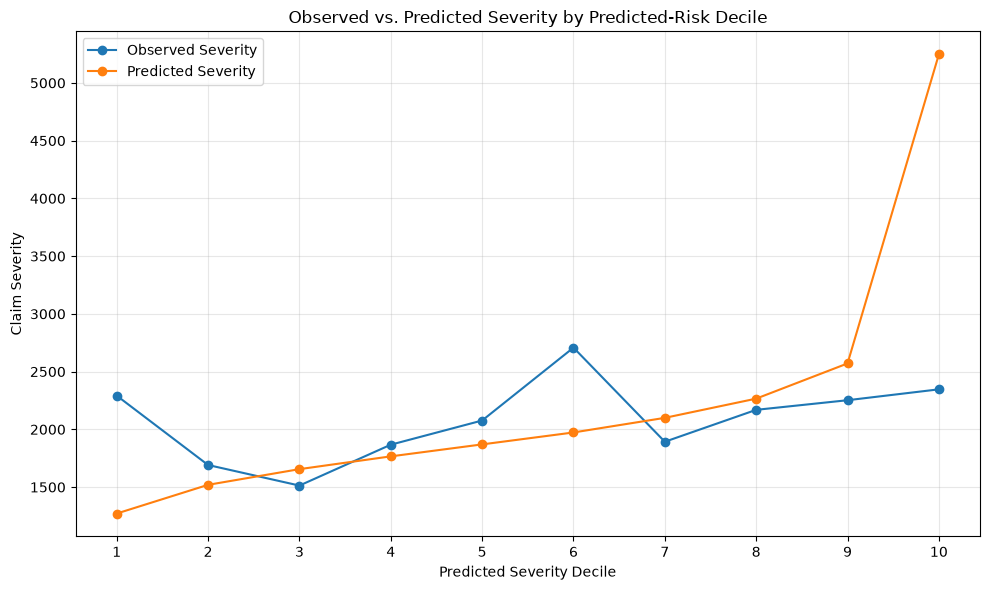

In [25]:
severity_calibration_plot = (
    severity_calibration
    .reset_index()
)

plt.figure(figsize=(10, 6))

plt.plot(
    severity_calibration_plot["severity_decile"],
    severity_calibration_plot["observed_severity"],
    marker="o",
    label="Observed Severity",
)

plt.plot(
    severity_calibration_plot["severity_decile"],
    severity_calibration_plot["predicted_severity"],
    marker="o",
    label="Predicted Severity",
)

plt.xlabel("Predicted Severity Decile")
plt.ylabel("Claim Severity")
plt.title("Observed vs. Predicted Severity by Predicted-Risk Decile")
plt.xticks(range(1, 11))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Ergebnis:** Die beobachtete Schadenhöhe steigt über die prognostizierten
Severity-Dezile nicht konsistent an. Insbesondere im höchsten Dezil
überschätzt das Modell die tatsächliche Schadenhöhe deutlich.

Damit zeigt das Severity-Modell auf dem Holdout-Datensatz nur eine begrenzte
Risikodifferenzierung und Kalibrierung. Die Ergebnisse stimmen mit der
schwächeren Holdout-Leistung gegenüber der Baseline überein.

### Modellentscheidung für die weitere Verwendung

Die Spline-Gamma-Spezifikation wird auf Basis der Cross-Validation als
Severity-Modell beibehalten. Obwohl sie die konstante Baseline auf dem
Holdout-Testdatensatz nicht übertrifft, wird die Modellauswahl nicht nachträglich
an das Testergebnis angepasst.

Die schwächere Holdout-Generalisation wird als Modelllimitierung dokumentiert
und bei der späteren Pure-Premium-Bewertung berücksichtigt.

In [26]:
import joblib


MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

SEVERITY_MODEL_PATH = (
    MODEL_DIR
    / "severity_gamma_spline_holdout_v1.joblib"
)

joblib.dump(
    final_severity_pipeline,
    SEVERITY_MODEL_PATH,
)

print(f"Saved model: {SEVERITY_MODEL_PATH}")
print(f"Exists:      {SEVERITY_MODEL_PATH.exists()}")
print(
    f"Size:        "
    f"{SEVERITY_MODEL_PATH.stat().st_size / 1024:.2f} KB"
)

Saved model: c:\Users\Mesut\Desktop\kfz-insurance-risk-platform\models\severity_gamma_spline_holdout_v1.joblib
Exists:      True
Size:        7.84 KB


### Validierung des gespeicherten Modellartefakts

Das gespeicherte Severity-Modell wird erneut geladen und auf dem identischen
Holdout-Testdatensatz ausgeführt.

Damit wird geprüft, ob das gespeicherte Pipeline-Artefakt die ursprünglichen
Prognosen vollständig reproduziert.

In [27]:
loaded_severity_pipeline = joblib.load(
    SEVERITY_MODEL_PATH
)

loaded_severity_pred_test = (
    loaded_severity_pipeline.predict(
        X_severity_test
    )
)

predictions_identical = np.array_equal(
    final_severity_pred_test,
    loaded_severity_pred_test,
)

max_abs_difference = np.max(
    np.abs(
        final_severity_pred_test
        - loaded_severity_pred_test
    )
)

print("=== Severity Artifact Validation ===")
print(f"Predictions:             {len(loaded_severity_pred_test):,}")
print(f"Predictions identical:   {predictions_identical}")
print(f"Maximum abs. difference: {max_abs_difference:.12f}")

=== Severity Artifact Validation ===
Predictions:             4,999
Predictions identical:   True
Maximum abs. difference: 0.000000000000


**Ergebnis:** Das evaluierte Severity-Modell wurde erfolgreich als
reproduzierbares Pipeline-Artefakt gespeichert und erneut geladen.

Die Vorhersagen des gespeicherten Modells stimmen exakt mit den
ursprünglichen Holdout-Prognosen überein.

## Post-Audit-Validierung des Severity-Modells

Die ursprüngliche Modellauswahl basierte auf einer 5-Fold-Cross-Validation.
Aufgrund der ausgeprägten Heavy-Tail-Struktur zeigten die einzelnen Folds
jedoch deutliche Schwankungen.

Nach einer unabhängigen technischen Prüfung wird die Stabilität der
Modellentscheidung deshalb zusätzlich mit wiederholter, stratifizierter
Cross-Validation und gepoolten Out-of-Fold-Prognosen untersucht.

Der Holdout-Datensatz wird für diese Modellauswahl nicht verwendet.

In [28]:
from sklearn.model_selection import StratifiedKFold


severity_cv_seeds = [
    42,
    7,
    123,
    2024,
    99,
]

severity_strata = pd.qcut(
    y_severity_train.rank(method="first"),
    q=5,
    labels=False,
)

severity_v2_results = []


current_severity_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            ColumnTransformer(
                transformers=[
                    (
                        "categorical",
                        OneHotEncoder(
                            handle_unknown="ignore",
                            drop="first",
                        ),
                        severity_fixed_categorical,
                    ),
                    (
                        "spline",
                        SplineTransformer(
                            n_knots=6,
                            degree=3,
                            include_bias=False,
                        ),
                        severity_raw_numeric,
                    ),
                    (
                        "numeric",
                        "passthrough",
                        severity_density_feature,
                    ),
                ],
                remainder="drop",
            ),
        ),
        (
            "model",
            GammaRegressor(
                alpha=0.0,
                max_iter=1000,
            ),
        ),
    ]
)


for seed in severity_cv_seeds:

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed,
    )

    oof_baseline_pred = np.empty(
        len(X_severity_train),
        dtype=float,
    )

    oof_spline_pred = np.empty(
        len(X_severity_train),
        dtype=float,
    )

    fold_results = []

    for fold, (fit_idx, val_idx) in enumerate(
        cv.split(
            X_severity_train,
            severity_strata,
        ),
        start=1,
    ):
        X_fit = X_severity_train.iloc[fit_idx]
        X_val = X_severity_train.iloc[val_idx]

        y_fit = y_severity_train.iloc[fit_idx]
        y_val = y_severity_train.iloc[val_idx]

        w_fit = w_severity_train.iloc[fit_idx]
        w_val = w_severity_train.iloc[val_idx]

        fold_baseline = np.average(
            y_fit,
            weights=w_fit,
        )

        baseline_pred = np.full(
            len(y_val),
            fold_baseline,
            dtype=float,
        )

        fold_pipeline = clone(
            current_severity_pipeline
        )

        fold_pipeline.fit(
            X_fit,
            y_fit,
            model__sample_weight=w_fit,
        )

        spline_pred = fold_pipeline.predict(
            X_val
        )

        oof_baseline_pred[val_idx] = baseline_pred
        oof_spline_pred[val_idx] = spline_pred

        baseline_fold_deviance = (
            mean_gamma_deviance(
                y_val,
                baseline_pred,
                sample_weight=w_val,
            )
        )

        spline_fold_deviance = (
            mean_gamma_deviance(
                y_val,
                spline_pred,
                sample_weight=w_val,
            )
        )

        fold_results.append({
            "fold": fold,
            "baseline": baseline_fold_deviance,
            "spline": spline_fold_deviance,
            "spline_wins": (
                spline_fold_deviance
                < baseline_fold_deviance
            ),
        })

    pooled_baseline_deviance = (
        mean_gamma_deviance(
            y_severity_train,
            oof_baseline_pred,
            sample_weight=w_severity_train,
        )
    )

    pooled_spline_deviance = (
        mean_gamma_deviance(
            y_severity_train,
            oof_spline_pred,
            sample_weight=w_severity_train,
        )
    )

    improvement_pct = (
        (
            pooled_baseline_deviance
            - pooled_spline_deviance
        )
        / pooled_baseline_deviance
    )

    severity_v2_results.append({
        "seed": seed,
        "baseline_pooled_deviance": (
            pooled_baseline_deviance
        ),
        "spline_pooled_deviance": (
            pooled_spline_deviance
        ),
        "improvement_pct": improvement_pct,
        "folds_won_by_spline": sum(
            result["spline_wins"]
            for result in fold_results
        ),
    })


severity_v2_results_df = pd.DataFrame(
    severity_v2_results
)

display(severity_v2_results_df)

print("\n=== Repeated CV Summary ===")
print(
    "Baseline pooled deviance: "
    f"{severity_v2_results_df['baseline_pooled_deviance'].mean():.6f}"
)
print(
    "Spline pooled deviance:   "
    f"{severity_v2_results_df['spline_pooled_deviance'].mean():.6f}"
)
print(
    "Mean improvement:         "
    f"{severity_v2_results_df['improvement_pct'].mean():.2%}"
)
print(
    "Seeds won by Spline:      "
    f"{(
        severity_v2_results_df['spline_pooled_deviance']
        < severity_v2_results_df['baseline_pooled_deviance']
    ).sum()} / {len(severity_cv_seeds)}"
)

,seed,baseline_pooled_deviance,spline_pooled_deviance,improvement_pct,folds_won_by_spline
0,42,1.771934,1.634144,0.077762,3
1,7,1.754761,1.611078,0.081882,3
2,123,1.768503,1.648892,0.067634,2
3,2024,1.793907,1.731464,0.034809,2
4,99,1.761999,1.598127,0.093003,3



=== Repeated CV Summary ===
Baseline pooled deviance: 1.770221
Spline pooled deviance:   1.644741
Mean improvement:         7.10%
Seeds won by Spline:      5 / 5


### Ergebnis

Die wiederholte stratifizierte Cross-Validation bestätigt die ursprüngliche
Modellentscheidung deutlich robuster als die erste 5-Fold-Auswertung.

Das Spline-Modell erreicht über alle fünf Seeds eine niedrigere gepoolte
Out-of-Fold Gamma-Deviance als die jeweilige konstante Baseline. Die mittlere
Verbesserung beträgt **7,10 %**, und das Spline-Modell gewinnt in **5 von 5**
Wiederholungen.

Damit lässt sich die ursprüngliche CV-Verbesserung nicht ausschließlich durch
einen einzelnen günstigen Fold erklären. Die weiterhin schwächere
Holdout-Leistung zeigt jedoch, dass die Generalisierung des Severity-Modells
kritisch bleibt und die Regularisierung im nächsten Schritt erneut geprüft wird.

In [29]:
from sklearn.preprocessing import StandardScaler


severity_alpha_grid_v2 = [
    0.0,
    0.0001,
    0.001,
    0.01,
    0.1,
    1.0,
    10.0,
]

severity_alpha_results = []


for alpha in severity_alpha_grid_v2:

    seed_results = []

    for seed in severity_cv_seeds:

        cv = StratifiedKFold(
            n_splits=5,
            shuffle=True,
            random_state=seed,
        )

        oof_pred = np.empty(
            len(X_severity_train),
            dtype=float,
        )

        for fit_idx, val_idx in cv.split(
            X_severity_train,
            severity_strata,
        ):
            X_fit = X_severity_train.iloc[fit_idx]
            X_val = X_severity_train.iloc[val_idx]

            y_fit = y_severity_train.iloc[fit_idx]
            w_fit = w_severity_train.iloc[fit_idx]

            pipeline = Pipeline(
                steps=[
                    (
                        "preprocessor",
                        ColumnTransformer(
                            transformers=[
                                (
                                    "categorical",
                                    OneHotEncoder(
                                        handle_unknown="ignore",
                                        drop="first",
                                    ),
                                    severity_fixed_categorical,
                                ),
                                (
                                    "spline",
                                    SplineTransformer(
                                        n_knots=6,
                                        degree=3,
                                        include_bias=False,
                                    ),
                                    severity_raw_numeric,
                                ),
                                (
                                    "numeric",
                                    "passthrough",
                                    severity_density_feature,
                                ),
                            ],
                            remainder="drop",
                        ),
                    ),
                    (
                        "scaler",
                        StandardScaler(
                            with_mean=False
                        ),
                    ),
                    (
                        "model",
                        GammaRegressor(
                            alpha=alpha,
                            max_iter=2000,
                        ),
                    ),
                ]
            )

            pipeline.fit(
                X_fit,
                y_fit,
                model__sample_weight=w_fit,
            )

            oof_pred[val_idx] = pipeline.predict(
                X_val
            )

        pooled_deviance = mean_gamma_deviance(
            y_severity_train,
            oof_pred,
            sample_weight=w_severity_train,
        )

        seed_results.append(
            pooled_deviance
        )

    severity_alpha_results.append({
        "alpha": alpha,
        "mean_pooled_deviance": np.mean(
            seed_results
        ),
        "std_pooled_deviance": np.std(
            seed_results,
            ddof=1,
        ),
        "min_pooled_deviance": np.min(
            seed_results
        ),
        "max_pooled_deviance": np.max(
            seed_results
        ),
    })


severity_alpha_results_df = (
    pd.DataFrame(severity_alpha_results)
    .sort_values("mean_pooled_deviance")
    .reset_index(drop=True)
)

display(severity_alpha_results_df)

best_alpha_v2 = severity_alpha_results_df.loc[
    0,
    "alpha",
]

print(
    f"\nBest alpha by repeated pooled OOF deviance: "
    f"{best_alpha_v2}"
)

,alpha,mean_pooled_deviance,std_pooled_deviance,min_pooled_deviance,max_pooled_deviance
0,0.1000,1.648232,0.047891,1.603360,1.725233
1,1.0000,1.650246,0.043500,1.611077,1.717797
2,0.0100,1.658165,0.056213,1.598543,1.733690
3,10.0000,1.693934,0.034350,1.661798,1.747963
4,0.0010,1.799166,0.336899,1.598165,2.394307
5,0.0001,1.886577,0.529869,1.598141,2.829681
6,0.0000,1.900259,0.560068,1.598150,2.897622



Best alpha by repeated pooled OOF deviance: 0.1


### Ergebnis

Nach Standardisierung der gesamten transformierten Design-Matrix erreicht
`alpha = 0,1` innerhalb dieser Variante die niedrigste mittlere gepoolte
OOF-Gamma-Deviance von **1,6482**.

Die bisherige unskalierte Spline-Spezifikation erreicht in der wiederholten
Validierung jedoch weiterhin einen leicht niedrigeren Wert von **1,6447**.
Eine stärkere Regularisierung ist damit noch nicht als Verbesserung bestätigt.

Die starke Instabilität sehr kleiner Alpha-Werte nach vollständiger Skalierung
zeigt außerdem, dass die Skalierungsstrategie differenzierter geprüft werden
muss. Im nächsten Schritt werden nur die numerischen und Spline-Komponenten
standardisiert, während die One-Hot-kodierten Kategorien unverändert bleiben.

In [30]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


severity_alpha_grid_v3 = [
    0.0,
    0.0001,
    0.001,
    0.01,
    0.1,
    1.0,
    10.0,
]

severity_alpha_results_v3 = []


for alpha in severity_alpha_grid_v3:

    seed_results = []

    for seed in severity_cv_seeds:

        cv = StratifiedKFold(
            n_splits=5,
            shuffle=True,
            random_state=seed,
        )

        oof_pred = np.empty(
            len(X_severity_train),
            dtype=float,
        )

        for fit_idx, val_idx in cv.split(
            X_severity_train,
            severity_strata,
        ):
            X_fit = X_severity_train.iloc[fit_idx]
            X_val = X_severity_train.iloc[val_idx]

            y_fit = y_severity_train.iloc[fit_idx]
            w_fit = w_severity_train.iloc[fit_idx]

            spline_pipeline = Pipeline(
                steps=[
                    (
                        "spline",
                        SplineTransformer(
                            n_knots=6,
                            degree=3,
                            include_bias=False,
                        ),
                    ),
                    (
                        "scaler",
                        StandardScaler(),
                    ),
                ]
            )

            preprocessor = ColumnTransformer(
                transformers=[
                    (
                        "categorical",
                        OneHotEncoder(
                            handle_unknown="ignore",
                            drop="first",
                        ),
                        severity_fixed_categorical,
                    ),
                    (
                        "spline",
                        spline_pipeline,
                        severity_raw_numeric,
                    ),
                    (
                        "numeric",
                        StandardScaler(),
                        severity_density_feature,
                    ),
                ],
                remainder="drop",
            )

            pipeline = Pipeline(
                steps=[
                    (
                        "preprocessor",
                        preprocessor,
                    ),
                    (
                        "model",
                        GammaRegressor(
                            alpha=alpha,
                            max_iter=3000,
                        ),
                    ),
                ]
            )

            pipeline.fit(
                X_fit,
                y_fit,
                model__sample_weight=w_fit,
            )

            oof_pred[val_idx] = pipeline.predict(
                X_val
            )

        pooled_deviance = mean_gamma_deviance(
            y_severity_train,
            oof_pred,
            sample_weight=w_severity_train,
        )

        seed_results.append(
            pooled_deviance
        )

    severity_alpha_results_v3.append({
        "alpha": alpha,
        "mean_pooled_deviance": np.mean(
            seed_results
        ),
        "std_pooled_deviance": np.std(
            seed_results,
            ddof=1,
        ),
        "min_pooled_deviance": np.min(
            seed_results
        ),
        "max_pooled_deviance": np.max(
            seed_results
        ),
    })


severity_alpha_results_v3_df = (
    pd.DataFrame(
        severity_alpha_results_v3
    )
    .sort_values(
        "mean_pooled_deviance"
    )
    .reset_index(drop=True)
)

display(
    severity_alpha_results_v3_df
)

best_alpha_v3 = (
    severity_alpha_results_v3_df.loc[
        0,
        "alpha",
    ]
)

print(
    "\nCurrent unscaled Spline: "
    f"{severity_v2_results_df['spline_pooled_deviance'].mean():.6f}"
)

print(
    "Best selectively scaled model: "
    f"{severity_alpha_results_v3_df.loc[0, 'mean_pooled_deviance']:.6f}"
)

print(
    f"Best selectively scaled alpha: "
    f"{best_alpha_v3}"
)

,alpha,mean_pooled_deviance,std_pooled_deviance,min_pooled_deviance,max_pooled_deviance
0,0.1000,1.618098e+00,5.348356e-02,1.576110,1.708795e+00
1,1.0000,1.632811e+00,4.874926e-02,1.595191,1.714399e+00
2,0.0100,1.641655e+00,5.765777e-02,1.583529,1.721247e+00
3,10.0000,1.690924e+00,3.591663e-02,1.659299,1.749352e+00
4,0.0010,3.144626e+00,2.966755e+00,1.594237,8.411499e+00
5,0.0001,1.299271e+16,2.905258e+16,1.597674,6.496355e+16
6,0.0000,2.153882e+28,4.816226e+28,1.598180,1.076941e+29



Current unscaled Spline: 1.644741
Best selectively scaled model: 1.618098
Best selectively scaled alpha: 0.1


### Ergebnis

Die selektive Standardisierung der numerischen und Spline-Komponenten
verbessert die wiederholte Cross-Validation deutlich.

Mit `alpha = 0,1` erreicht das Modell eine mittlere gepoolte
OOF-Gamma-Deviance von **1,6181** und liegt damit unter der bisherigen
unskalierten Spline-Spezifikation mit **1,6447**.

Sehr kleine Alpha-Werte zeigen dagegen eine starke numerische Instabilität.
Die Ergebnisse sprechen deshalb für eine moderate Regularisierung der
skalierten Severity-Spezifikation.

Die Modellauswahl erfolgt weiterhin ausschließlich auf den Trainingsdaten;
der Holdout wird in diesem Schritt nicht verwendet.

In [31]:
scaled_best_seed_results = []

for seed in severity_cv_seeds:

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed,
    )

    oof_pred = np.empty(
        len(X_severity_train),
        dtype=float,
    )

    fold_iterations = []

    for fit_idx, val_idx in cv.split(
        X_severity_train,
        severity_strata,
    ):
        X_fit = X_severity_train.iloc[fit_idx]
        X_val = X_severity_train.iloc[val_idx]

        y_fit = y_severity_train.iloc[fit_idx]
        w_fit = w_severity_train.iloc[fit_idx]

        spline_pipeline = Pipeline(
            steps=[
                (
                    "spline",
                    SplineTransformer(
                        n_knots=6,
                        degree=3,
                        include_bias=False,
                    ),
                ),
                (
                    "scaler",
                    StandardScaler(),
                ),
            ]
        )

        preprocessor = ColumnTransformer(
            transformers=[
                (
                    "categorical",
                    OneHotEncoder(
                        handle_unknown="ignore",
                        drop="first",
                    ),
                    severity_fixed_categorical,
                ),
                (
                    "spline",
                    spline_pipeline,
                    severity_raw_numeric,
                ),
                (
                    "numeric",
                    StandardScaler(),
                    severity_density_feature,
                ),
            ],
            remainder="drop",
        )

        pipeline = Pipeline(
            steps=[
                (
                    "preprocessor",
                    preprocessor,
                ),
                (
                    "model",
                    GammaRegressor(
                        alpha=0.1,
                        max_iter=3000,
                    ),
                ),
            ]
        )

        pipeline.fit(
            X_fit,
            y_fit,
            model__sample_weight=w_fit,
        )

        oof_pred[val_idx] = pipeline.predict(
            X_val
        )

        fold_iterations.append(
            pipeline.named_steps["model"].n_iter_
        )

    pooled_deviance = mean_gamma_deviance(
        y_severity_train,
        oof_pred,
        sample_weight=w_severity_train,
    )

    scaled_best_seed_results.append({
        "seed": seed,
        "scaled_alpha_01_deviance": pooled_deviance,
        "max_iterations": max(fold_iterations),
        "max_prediction": oof_pred.max(),
    })


scaled_best_seed_df = pd.DataFrame(
    scaled_best_seed_results
)

severity_candidate_comparison = (
    severity_v2_results_df[
        [
            "seed",
            "baseline_pooled_deviance",
            "spline_pooled_deviance",
        ]
    ]
    .merge(
        scaled_best_seed_df,
        on="seed",
        how="left",
    )
    .rename(
        columns={
            "spline_pooled_deviance":
                "current_unscaled_deviance",
        }
    )
)

severity_candidate_comparison[
    "scaled_beats_current"
] = (
    severity_candidate_comparison[
        "scaled_alpha_01_deviance"
    ]
    < severity_candidate_comparison[
        "current_unscaled_deviance"
    ]
)

severity_candidate_comparison[
    "scaled_beats_baseline"
] = (
    severity_candidate_comparison[
        "scaled_alpha_01_deviance"
    ]
    < severity_candidate_comparison[
        "baseline_pooled_deviance"
    ]
)

display(severity_candidate_comparison)

print("\n=== Candidate Stability Check ===")

print(
    "Baseline mean:       "
    f"{severity_candidate_comparison['baseline_pooled_deviance'].mean():.6f}"
)

print(
    "Current Spline mean: "
    f"{severity_candidate_comparison['current_unscaled_deviance'].mean():.6f}"
)

print(
    "Scaled alpha=0.1:    "
    f"{severity_candidate_comparison['scaled_alpha_01_deviance'].mean():.6f}"
)

print(
    "Scaled beats current: "
    f"{severity_candidate_comparison['scaled_beats_current'].sum()} / "
    f"{len(severity_candidate_comparison)} seeds"
)

print(
    "Scaled beats baseline: "
    f"{severity_candidate_comparison['scaled_beats_baseline'].sum()} / "
    f"{len(severity_candidate_comparison)} seeds"
)

,seed,baseline_pooled_deviance,current_unscaled_deviance,scaled_alpha_01_deviance,max_iterations,max_prediction,scaled_beats_current,scaled_beats_baseline
0,42,1.771934,1.634144,1.606913,23,20752.224677,True,True
1,7,1.754761,1.611078,1.581674,24,20410.356060,True,True
2,123,1.768503,1.648892,1.616999,24,21958.718812,True,True
3,2024,1.793907,1.731464,1.708795,24,20485.714720,True,True
4,99,1.761999,1.598127,1.576110,24,21088.116575,True,True



=== Candidate Stability Check ===
Baseline mean:       1.770221
Current Spline mean: 1.644741
Scaled alpha=0.1:    1.618098
Scaled beats current: 5 / 5 seeds
Scaled beats baseline: 5 / 5 seeds


### Ergebnis

Die selektiv standardisierte Severity-Spezifikation mit `alpha = 0,1`
übertrifft sowohl die bisherige unskalierte Spline-Spezifikation als auch
die konstante Baseline in **allen fünf Wiederholungen**.

Die mittlere gepoolte OOF-Gamma-Deviance verbessert sich von **1,6447**
auf **1,6181**. Gleichzeitig konvergiert das Modell in allen Folds stabil.

Damit ist die Verbesserung nicht auf einen einzelnen zufälligen Split
zurückzuführen. Vor der endgültigen Modellauswahl wird zusätzlich geprüft,
ob eine stärker regularisierte Spezifikation nach dem 1-SE-Prinzip eine
vergleichbare Leistung bei höherer Modellstabilität bietet.

In [32]:
best_row_v3 = severity_alpha_results_v3_df.iloc[0]

best_mean_v3 = best_row_v3["mean_pooled_deviance"]

best_se_v3 = (
    best_row_v3["std_pooled_deviance"]
    / np.sqrt(len(severity_cv_seeds))
)

one_se_threshold = (
    best_mean_v3 + best_se_v3
)

one_se_candidates = (
    severity_alpha_results_v3_df.loc[
        severity_alpha_results_v3_df[
            "mean_pooled_deviance"
        ] <= one_se_threshold
    ]
    .sort_values(
        "alpha",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(one_se_candidates)

selected_alpha_1se = (
    one_se_candidates.loc[
        0,
        "alpha",
    ]
)

print(
    f"Best mean deviance:       "
    f"{best_mean_v3:.6f}"
)

print(
    f"Standard error:           "
    f"{best_se_v3:.6f}"
)

print(
    f"1-SE threshold:           "
    f"{one_se_threshold:.6f}"
)

print(
    f"Best alpha by mean:       "
    f"{best_alpha_v3}"
)

print(
    f"Selected alpha by 1-SE:   "
    f"{selected_alpha_1se}"
)

,alpha,mean_pooled_deviance,std_pooled_deviance,min_pooled_deviance,max_pooled_deviance
0,1.00,1.632811,0.048749,1.595191,1.714399
1,0.10,1.618098,0.053484,1.576110,1.708795
2,0.01,1.641655,0.057658,1.583529,1.721247


Best mean deviance:       1.618098
Standard error:           0.023919
1-SE threshold:           1.642017
Best alpha by mean:       0.1
Selected alpha by 1-SE:   1.0


### Ergebnis

Nach dem 1-SE-Prinzip liegt neben `alpha = 0,1` auch die stärker
regularisierte Spezifikation mit `alpha = 1,0` innerhalb des
akzeptierten Leistungsbereichs.

Obwohl `alpha = 0,1` mit einer mittleren gepoolten OOF-Gamma-Deviance
von **1,6181** den numerisch besten Wert erreicht, wird `alpha = 1,0`
als finaler Severity-v2-Kandidat gewählt.

Diese Spezifikation bietet eine stärkere Regularisierung bei vergleichbarer
Cross-Validation-Leistung und reduziert damit das Risiko einer instabilen
Anpassung an die ausgeprägte Heavy-Tail-Struktur.

Die Auswahl wurde ausschließlich anhand der Trainingsdaten getroffen.

In [34]:
final_severity_v2_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first",
            ),
            severity_fixed_categorical,
        ),
        (
            "spline",
            Pipeline(
                steps=[
                    (
                        "spline",
                        SplineTransformer(
                            n_knots=6,
                            degree=3,
                            include_bias=False,
                        ),
                    ),
                    (
                        "scaler",
                        StandardScaler(),
                    ),
                ]
            ),
            severity_raw_numeric,
        ),
        (
            "numeric",
            StandardScaler(),
            severity_density_feature,
        ),
    ],
    remainder="drop",
)

final_severity_v2_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            final_severity_v2_preprocessor,
        ),
        (
            "model",
            GammaRegressor(
                alpha=1.0,
                max_iter=3000,
            ),
        ),
    ]
)

final_severity_v2_pipeline.fit(
    X_severity_train,
    y_severity_train,
    model__sample_weight=w_severity_train,
)

severity_v2_test_pred = (
    final_severity_v2_pipeline.predict(
        X_severity_test
    )
)

severity_v2_test_deviance = mean_gamma_deviance(
    y_severity_test,
    severity_v2_test_pred,
    sample_weight=w_severity_test,
)

severity_v2_d2 = (
    1
    - severity_v2_test_deviance
    / baseline_gamma_deviance
)

severity_v2_predicted_amount = np.sum(
    severity_v2_test_pred
    * w_severity_test
)

severity_v2_actual_amount = np.sum(
    y_severity_test
    * w_severity_test
)

severity_v2_amount_difference_pct = (
    (
        severity_v2_predicted_amount
        - severity_v2_actual_amount
    )
    / severity_v2_actual_amount
)

severity_v2_weighted_mean = np.average(
    severity_v2_test_pred,
    weights=w_severity_test,
)

actual_weighted_severity_v2 = np.average(
    y_severity_test,
    weights=w_severity_test,
)

print("=== Severity v2 — Holdout Confirmation ===")

print(
    f"Baseline Gamma Deviance:       "
    f"{baseline_gamma_deviance:.6f}"
)

print(
    f"Severity v1 Gamma Deviance:    "
    f"{final_gamma_deviance:.6f}"
)

print(
    f"Severity v2 Gamma Deviance:    "
    f"{severity_v2_test_deviance:.6f}"
)

print(
    f"Severity v2 D²:                "
    f"{severity_v2_d2:.4f}"
)

print(
    f"Actual weighted severity:      "
    f"{actual_weighted_severity_v2:,.2f}"
)

print(
    f"Predicted weighted severity:   "
    f"{severity_v2_weighted_mean:,.2f}"
)

print(
    f"Claim amount difference:       "
    f"{severity_v2_amount_difference_pct:.2%}"
)

print(
    f"Iterations:                    "
    f"{final_severity_v2_pipeline.named_steps['model'].n_iter_}"
)

=== Severity v2 — Holdout Confirmation ===
Baseline Gamma Deviance:       1.543630
Severity v1 Gamma Deviance:    1.615760
Severity v2 Gamma Deviance:    1.567498
Severity v2 D²:                -0.0155
Actual weighted severity:      2,081.27
Predicted weighted severity:   2,164.21
Claim amount difference:       3.99%
Iterations:                    11


### Ergebnis

Die nach dem erweiterten Train-CV-Protokoll ausgewählte Severity-v2-
Spezifikation verbessert die Holdout-Leistung deutlich gegenüber dem
ursprünglichen Modell.

Die Gamma-Deviance sinkt von **1,6158 auf 1,5675**, während sich die
Abweichung der schadengewichteten durchschnittlichen Schadenhöhe von
**+7,19 % auf +3,99 %** reduziert.

Gegenüber der konstanten Holdout-Baseline von **1,5436** bleibt die
Severity-v2-Spezifikation jedoch leicht schwächer. Das Gamma-D² verbessert
sich deutlich von **−0,0540 auf −0,0155**, bleibt aber weiterhin negativ.

Damit bestätigt sich, dass Regularisierung und selektive Skalierung die
Stabilität und Generalisierung verbessern, die verfügbaren Risikomerkmale
die Schadenhöhe jedoch weiterhin nur begrenzt erklären.

## Large-Loss-Sensitivitätsanalyse

Die Severity-Verteilung weist einen ausgeprägten Heavy Tail auf. Daher wird
abschließend geprüft, ob eine Trennung zwischen attritionaler Schadenhöhe und
einem pauschalen Large-Loss-Loading die Out-of-Fold-Leistung stabilisiert.

Die Kappungsgrenze und das Large-Loss-Loading werden ausschließlich innerhalb
des jeweiligen Trainings-Folds bestimmt. Die Bewertung erfolgt weiterhin auf
der **ungekappten ursprünglichen Severity**, sodass keine künstliche
Verbesserung der Modellmetrik entsteht.

Die bereits ausgewählte Severity-v2-Spezifikation mit `alpha = 1,0` bleibt
unverändert. Dadurch wird ausschließlich der Effekt der Large-Loss-Behandlung
untersucht.

In [35]:
def make_severity_v2_pipeline(
    alpha: float = 1.0,
) -> Pipeline:
    """Build the selectively scaled Severity-v2 pipeline."""

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore",
                    drop="first",
                ),
                severity_fixed_categorical,
            ),
            (
                "spline",
                Pipeline(
                    steps=[
                        (
                            "spline",
                            SplineTransformer(
                                n_knots=6,
                                degree=3,
                                include_bias=False,
                            ),
                        ),
                        (
                            "scaler",
                            StandardScaler(),
                        ),
                    ]
                ),
                severity_raw_numeric,
            ),
            (
                "numeric",
                StandardScaler(),
                severity_density_feature,
            ),
        ],
        remainder="drop",
    )

    return Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor,
            ),
            (
                "model",
                GammaRegressor(
                    alpha=alpha,
                    max_iter=3000,
                ),
            ),
        ]
    )


large_loss_cap_specs = [
    ("p95", "quantile", 0.95),
    ("p99", "quantile", 0.99),
    ("p99.5", "quantile", 0.995),
    ("50k", "fixed", 50_000.0),
    ("100k", "fixed", 100_000.0),
]

large_loss_results = []


for seed in severity_cv_seeds:

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed,
    )

    cv_splits = list(
        cv.split(
            X_severity_train,
            severity_strata,
        )
    )

    oof_baseline_pred = np.empty(
        len(X_severity_train),
        dtype=float,
    )

    oof_uncapped_v2_pred = np.empty(
        len(X_severity_train),
        dtype=float,
    )

    # Baseline and uncapped Severity-v2
    for fit_idx, val_idx in cv_splits:

        X_fit = X_severity_train.iloc[fit_idx]
        X_val = X_severity_train.iloc[val_idx]

        y_fit = y_severity_train.iloc[fit_idx]
        w_fit = w_severity_train.iloc[fit_idx]

        fold_baseline = np.average(
            y_fit,
            weights=w_fit,
        )

        oof_baseline_pred[val_idx] = (
            fold_baseline
        )

        uncapped_pipeline = (
            make_severity_v2_pipeline(
                alpha=1.0
            )
        )

        uncapped_pipeline.fit(
            X_fit,
            y_fit,
            model__sample_weight=w_fit,
        )

        oof_uncapped_v2_pred[val_idx] = (
            uncapped_pipeline.predict(
                X_val
            )
        )

    baseline_deviance = mean_gamma_deviance(
        y_severity_train,
        oof_baseline_pred,
        sample_weight=w_severity_train,
    )

    uncapped_v2_deviance = (
        mean_gamma_deviance(
            y_severity_train,
            oof_uncapped_v2_pred,
            sample_weight=w_severity_train,
        )
    )

    # Large-loss candidates
    for cap_name, cap_type, cap_parameter in (
        large_loss_cap_specs
    ):

        oof_large_loss_pred = np.empty(
            len(X_severity_train),
            dtype=float,
        )

        fold_cap_values = []
        fold_loadings = []

        for fit_idx, val_idx in cv_splits:

            X_fit = X_severity_train.iloc[
                fit_idx
            ]
            X_val = X_severity_train.iloc[
                val_idx
            ]

            y_fit = y_severity_train.iloc[
                fit_idx
            ]
            w_fit = w_severity_train.iloc[
                fit_idx
            ]

            if cap_type == "quantile":
                cap_value = y_fit.quantile(
                    cap_parameter
                )
            else:
                cap_value = cap_parameter

            y_fit_capped = y_fit.clip(
                upper=cap_value
            )

            uncapped_mean = np.average(
                y_fit,
                weights=w_fit,
            )

            capped_mean = np.average(
                y_fit_capped,
                weights=w_fit,
            )

            large_loss_loading = (
                uncapped_mean
                - capped_mean
            )

            capped_pipeline = (
                make_severity_v2_pipeline(
                    alpha=1.0
                )
            )

            capped_pipeline.fit(
                X_fit,
                y_fit_capped,
                model__sample_weight=w_fit,
            )

            attritional_pred = (
                capped_pipeline.predict(
                    X_val
                )
            )

            final_pred = (
                attritional_pred
                + large_loss_loading
            )

            oof_large_loss_pred[val_idx] = (
                final_pred
            )

            fold_cap_values.append(
                cap_value
            )

            fold_loadings.append(
                large_loss_loading
            )

        capped_deviance = (
            mean_gamma_deviance(
                y_severity_train,
                oof_large_loss_pred,
                sample_weight=w_severity_train,
            )
        )

        large_loss_results.append({
            "seed": seed,
            "cap": cap_name,
            "baseline_deviance": (
                baseline_deviance
            ),
            "uncapped_v2_deviance": (
                uncapped_v2_deviance
            ),
            "large_loss_deviance": (
                capped_deviance
            ),
            "mean_cap_value": np.mean(
                fold_cap_values
            ),
            "mean_large_loss_loading": np.mean(
                fold_loadings
            ),
        })


large_loss_results_df = pd.DataFrame(
    large_loss_results
)

large_loss_results_df[
    "beats_uncapped_v2"
] = (
    large_loss_results_df[
        "large_loss_deviance"
    ]
    < large_loss_results_df[
        "uncapped_v2_deviance"
    ]
)

large_loss_results_df[
    "beats_baseline"
] = (
    large_loss_results_df[
        "large_loss_deviance"
    ]
    < large_loss_results_df[
        "baseline_deviance"
    ]
)


large_loss_summary = (
    large_loss_results_df
    .groupby(
        "cap",
        as_index=False,
    )
    .agg(
        mean_large_loss_deviance=(
            "large_loss_deviance",
            "mean",
        ),
        std_large_loss_deviance=(
            "large_loss_deviance",
            "std",
        ),
        mean_uncapped_v2_deviance=(
            "uncapped_v2_deviance",
            "mean",
        ),
        mean_baseline_deviance=(
            "baseline_deviance",
            "mean",
        ),
        wins_vs_uncapped_v2=(
            "beats_uncapped_v2",
            "sum",
        ),
        wins_vs_baseline=(
            "beats_baseline",
            "sum",
        ),
        mean_cap_value=(
            "mean_cap_value",
            "mean",
        ),
        mean_large_loss_loading=(
            "mean_large_loss_loading",
            "mean",
        ),
    )
    .sort_values(
        "mean_large_loss_deviance"
    )
    .reset_index(drop=True)
)

display(large_loss_summary)

best_large_loss_candidate = (
    large_loss_summary.iloc[0]
)

print(
    "\n=== Large-Loss CV Summary ==="
)

print(
    f"Baseline mean:              "
    f"{best_large_loss_candidate['mean_baseline_deviance']:.6f}"
)

print(
    f"Uncapped Severity-v2 mean:  "
    f"{best_large_loss_candidate['mean_uncapped_v2_deviance']:.6f}"
)

print(
    f"Best cap:                   "
    f"{best_large_loss_candidate['cap']}"
)

print(
    f"Best Large-Loss mean:       "
    f"{best_large_loss_candidate['mean_large_loss_deviance']:.6f}"
)

print(
    f"Wins vs uncapped v2:        "
    f"{int(best_large_loss_candidate['wins_vs_uncapped_v2'])} / "
    f"{len(severity_cv_seeds)} seeds"
)

print(
    f"Wins vs baseline:           "
    f"{int(best_large_loss_candidate['wins_vs_baseline'])} / "
    f"{len(severity_cv_seeds)} seeds"
)

print(
    f"Mean Large-Loss loading:    "
    f"{best_large_loss_candidate['mean_large_loss_loading']:,.2f}"
)

,cap,mean_large_loss_deviance,std_large_loss_deviance,mean_uncapped_v2_deviance,mean_baseline_deviance,wins_vs_uncapped_v2,wins_vs_baseline,mean_cap_value,mean_large_loss_loading
0,100k,1.708883,0.017739,1.632811,1.770221,0,5,100000.000000,426.903028
1,50k,1.722925,0.014114,1.632811,1.770221,0,5,50000.000000,539.267524
2,p99.5,1.730512,0.013402,1.632811,1.770221,0,5,33564.948142,608.106389
3,p99,1.743499,0.012997,1.632811,1.770221,0,5,16212.949440,729.489861
4,p95,1.760831,0.014353,1.632811,1.770221,0,5,4658.214730,975.604901



=== Large-Loss CV Summary ===
Baseline mean:              1.770221
Uncapped Severity-v2 mean:  1.632811
Best cap:                   100k
Best Large-Loss mean:       1.708883
Wins vs uncapped v2:        0 / 5 seeds
Wins vs baseline:           5 / 5 seeds
Mean Large-Loss loading:    426.90


### Ergebnis

Die Large-Loss-Sensitivitätsanalyse verbessert die Severity-v2-
Spezifikation nicht.

Die beste Variante verwendet eine Kappungsgrenze von **100.000 €** und
erreicht eine mittlere gepoolte OOF-Gamma-Deviance von **1,7089**.
Damit liegt sie zwar unter der konstanten Baseline von **1,7702**, aber
deutlich über der ungekappten Severity-v2-Spezifikation mit **1,6328**.

Keine der fünf Wiederholungen zeigt einen Vorteil gegenüber dem
ungekappten Severity-v2-Modell. Die Large-Loss-Behandlung wird daher
nicht übernommen.

Die Severity-Modellierung wird an dieser Stelle bewusst abgeschlossen.
Die Ergebnisse zeigen, dass Regularisierung und selektive Skalierung die
Stabilität verbessern, während die verfügbaren Risikomerkmale die
individuelle Schadenhöhe weiterhin nur begrenzt erklären.

## Lorenz-Kurve und Gini-Koeffizient der Severity

Zusätzlich zur Gamma-Deviance wird geprüft, wie gut die Severity-Modelle
Schäden nach ihrer erwarteten Schadenhöhe sortieren.

Die Policen werden anhand der vorhergesagten Severity geordnet. Als Gewicht
wird die Anzahl der Schäden (`ClaimNb`) verwendet und der kumulierte
tatsächliche Schadenbetrag betrachtet.

Severity v1 und Severity v2 werden auf demselben Holdout-Datensatz verglichen.

In [36]:

if "final_severity_pred_test" not in globals():
    final_severity_pred_test = final_severity_pipeline.predict(
        X_severity_test
    )


def severity_lorenz_gini(
    predicted_severity,
    actual_severity,
    claim_weights,
):
    evaluation = pd.DataFrame({
        "predicted_severity": np.asarray(
            predicted_severity
        ),
        "actual_severity": np.asarray(
            actual_severity
        ),
        "claim_weight": np.asarray(
            claim_weights
        ),
    })

    evaluation["actual_claim_amount"] = (
        evaluation["actual_severity"]
        * evaluation["claim_weight"]
    )

    evaluation = (
        evaluation
        .sort_values(
            "predicted_severity",
            ascending=True,
        )
        .reset_index(drop=True)
    )

    cumulative_claim_weight = np.concatenate([
        [0.0],
        (
            evaluation["claim_weight"].cumsum()
            / evaluation["claim_weight"].sum()
        ).to_numpy(),
    ])

    cumulative_claim_amount = np.concatenate([
        [0.0],
        (
            evaluation["actual_claim_amount"].cumsum()
            / evaluation["actual_claim_amount"].sum()
        ).to_numpy(),
    ])

    lorenz_auc = np.trapezoid(
        cumulative_claim_amount,
        cumulative_claim_weight,
    )

    gini = 1 - 2 * lorenz_auc

    return (
        cumulative_claim_weight,
        cumulative_claim_amount,
        gini,
    )


(
    severity_v1_lorenz_x,
    severity_v1_lorenz_y,
    severity_v1_gini,
) = severity_lorenz_gini(
    final_severity_pred_test,
    y_severity_test,
    w_severity_test,
)

(
    severity_v2_lorenz_x,
    severity_v2_lorenz_y,
    severity_v2_gini,
) = severity_lorenz_gini(
    severity_v2_test_pred,
    y_severity_test,
    w_severity_test,
)


severity_gini_comparison = pd.DataFrame({
    "model": [
        "Severity v1",
        "Severity v2",
    ],
    "gini": [
        severity_v1_gini,
        severity_v2_gini,
    ],
})

display(severity_gini_comparison)

print("=== Severity Gini Comparison ===")

print(
    f"Severity v1 Gini: "
    f"{severity_v1_gini:.4f}"
)

print(
    f"Severity v2 Gini: "
    f"{severity_v2_gini:.4f}"
)

print(
    f"Gini improvement:  "
    f"{severity_v2_gini - severity_v1_gini:+.4f}"
)

,model,gini
0,Severity v1,0.033345
1,Severity v2,0.003292


=== Severity Gini Comparison ===
Severity v1 Gini: 0.0333
Severity v2 Gini: 0.0033
Gini improvement:  -0.0301


### Ergebnis

Die Severity-Modelle zeigen insgesamt nur eine sehr geringe
Risikodifferenzierung.

Der Gini-Koeffizient sinkt von **0,0333** bei Severity v1 auf **0,0033**
bei Severity v2. Damit verbessert Severity v2 zwar die Gamma-Deviance
und die Portfoliokalibrierung, verliert jedoch an Ranking-Fähigkeit.

Dieses Ergebnis bestätigt, dass die verfügbaren Risikomerkmale die
individuelle Schadenhöhe nur sehr begrenzt erklären. Die endgültige
Modellentscheidung wird daher nicht anhand einer einzelnen Kennzahl,
sondern unter gemeinsamer Betrachtung von Deviance, Kalibrierung und
Risk Ranking getroffen.

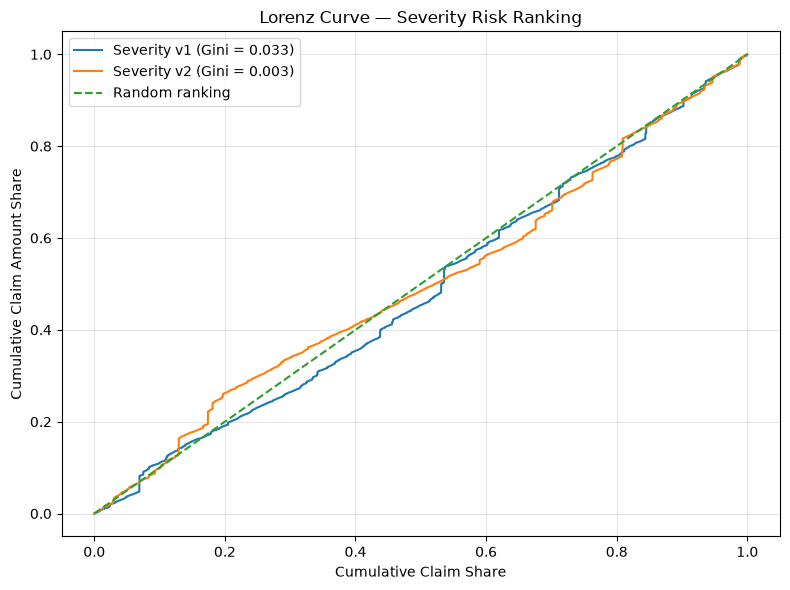

In [37]:
plt.figure(figsize=(8, 6))

plt.plot(
    severity_v1_lorenz_x,
    severity_v1_lorenz_y,
    label=f"Severity v1 (Gini = {severity_v1_gini:.3f})",
)

plt.plot(
    severity_v2_lorenz_x,
    severity_v2_lorenz_y,
    label=f"Severity v2 (Gini = {severity_v2_gini:.3f})",
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random ranking",
)

plt.xlabel("Cumulative Claim Share")
plt.ylabel("Cumulative Claim Amount Share")
plt.title("Lorenz Curve — Severity Risk Ranking")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [3]:
from pathlib import Path

import joblib
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import GammaRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    SplineTransformer,
    StandardScaler,
)


# --------------------------------------------------
# 1. Project paths
# --------------------------------------------------

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "policy_curated.pq"
)

SPLIT_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "policy_train_test_split.pq"
)


# --------------------------------------------------
# 2. Reload curated data + canonical split
# --------------------------------------------------

df = pd.read_parquet(DATA_PATH)
split_assignment = pd.read_parquet(SPLIT_PATH)

df["IDpol"] = df["IDpol"].astype("int64")
split_assignment["IDpol"] = split_assignment["IDpol"].astype("int64")

df_model = df.merge(
    split_assignment,
    on="IDpol",
    how="left",
    validate="one_to_one",
)


# --------------------------------------------------
# 3. Severity eligibility
# --------------------------------------------------

severity_mask = (
    df_model["ClaimNb"].gt(0)
    & df_model["total_claim_amount"].notna()
    & df_model["total_claim_amount"].gt(0)
    & ~df_model["missing_severity"]
    & ~df_model["claim_count_mismatch"]
)

severity_df = (
    df_model.loc[severity_mask]
    .copy()
)

severity_df["observed_severity_target"] = (
    severity_df["total_claim_amount"]
    / severity_df["ClaimNb"]
)

severity_train = (
    severity_df[
        severity_df["split"] == "train"
    ]
    .copy()
)

severity_test = (
    severity_df[
        severity_df["split"] == "test"
    ]
    .copy()
)


# --------------------------------------------------
# 4. Features, target and weights
# --------------------------------------------------

severity_fixed_categorical = [
    "VehPower",
    "VehBrand",
    "VehGas",
    "Region",
]

severity_raw_numeric = [
    "DrivAge",
    "VehAge",
    "BonusMalus",
]

severity_density_feature = [
    "log_density",
]

severity_features = (
    severity_fixed_categorical
    + severity_raw_numeric
    + severity_density_feature
)

X_severity_train = severity_train[
    severity_features
].copy()

X_severity_test = severity_test[
    severity_features
].copy()

y_severity_train = severity_train[
    "observed_severity_target"
].copy()

y_severity_test = severity_test[
    "observed_severity_target"
].copy()

w_severity_train = severity_train[
    "ClaimNb"
].copy()

w_severity_test = severity_test[
    "ClaimNb"
].copy()


# --------------------------------------------------
# 5. Rebuild locked Severity v2
# --------------------------------------------------

final_severity_v2_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first",
            ),
            severity_fixed_categorical,
        ),
        (
            "spline",
            Pipeline(
                steps=[
                    (
                        "spline",
                        SplineTransformer(
                            n_knots=6,
                            degree=3,
                            include_bias=False,
                        ),
                    ),
                    (
                        "scaler",
                        StandardScaler(),
                    ),
                ]
            ),
            severity_raw_numeric,
        ),
        (
            "numeric",
            StandardScaler(),
            severity_density_feature,
        ),
    ],
    remainder="drop",
)

final_severity_v2_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            final_severity_v2_preprocessor,
        ),
        (
            "model",
            GammaRegressor(
                alpha=1.0,
                max_iter=3000,
            ),
        ),
    ]
)

final_severity_v2_pipeline.fit(
    X_severity_train,
    y_severity_train,
    model__sample_weight=w_severity_train,
)


# --------------------------------------------------
# 6. Save artifact
# --------------------------------------------------

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SEVERITY_V2_MODEL_PATH = (
    MODEL_DIR
    / "severity_gamma_spline_scaled_holdout_v2.joblib"
)

joblib.dump(
    final_severity_v2_pipeline,
    SEVERITY_V2_MODEL_PATH,
)

print("=== Severity v2 Artifact ===")
print(f"Train policies: {len(severity_train):,}")
print(f"Test policies:  {len(severity_test):,}")
print(f"Saved:          {SEVERITY_V2_MODEL_PATH}")
print(f"Exists:         {SEVERITY_V2_MODEL_PATH.exists()}")

=== Severity v2 Artifact ===
Train policies: 19,944
Test policies:  4,999
Saved:          c:\Users\Mesut\Desktop\kfz-insurance-risk-platform\models\severity_gamma_spline_scaled_holdout_v2.joblib
Exists:         True
